# Predicting NFL Quarterback Success

## Research Hypothesis
College QB decision-making, negative-play avoidance,
pocket management, and efficient rushing value predict
NFL success better than traditional passing statistics.

## Objective
Construct and evaluate NFL quarterback performance
targets, beginning with EPA per dropback.

## Initial Dataset
NFL play-by-play data from nflverse, 2023 season.

### 2.1 - Install libraries

In [1]:
import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

### 2.2 - Load first dataset

In [2]:
pbp = nfl.load_pbp([2023]).to_pandas()
print("Dataset shape:", pbp.shape)
pbp.head()

Dataset shape: (49665, 372)


,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,side_of_field,yardline_100,game_date,quarter_seconds_remaining,half_seconds_remaining,game_seconds_remaining,game_half,quarter_end,drive,sp,qtr,down,goal_to_go,time,yrdln,ydstogo,ydsnet,desc,play_type,yards_gained,shotgun,no_huddle,qb_dropback,qb_kneel,qb_spike,qb_scramble,pass_length,pass_location,air_yards,yards_after_catch,run_location,run_gap,field_goal_result,kick_distance,extra_point_result,two_point_conv_result,home_timeouts_remaining,away_timeouts_remaining,timeout,timeout_team,...,drive_play_id_ended,away_score,home_score,location,result,total,spread_line,total_line,div_game,roof,surface,temp,wind,home_coach,away_coach,stadium_id,game_stadium,aborted_play,success,passer,passer_jersey_number,rusher,rusher_jersey_number,receiver,receiver_jersey_number,pass,rush,first_down,special,play,passer_id,rusher_id,receiver_id,name,jersey_number,id,fantasy_player_name,fantasy_player_id,fantasy,fantasy_id,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,NaN,NaN,NaN,NaN,NaN,2023-09-10,900.0,1800.0,3600.0,Half1,0.0,NaN,0.0,1.0,NaN,0,15:00,ARI 35,0.0,NaN,GAME,NaN,NaN,0.0,0.0,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.0,NaN,NaN,...,NaN,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,39.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,ARI,35.0,2023-09-10,900.0,1800.0,3600.0,Half1,0.0,1.0,0.0,1.0,NaN,0,15:00,ARI 35,0.0,26.0,5-M.Prater kicks 65 yards from ARI 35 to end z...,kickoff,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.0,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,55.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,WAS,75.0,2023-09-10,900.0,1800.0,3600.0,Half1,0.0,1.0,0.0,1.0,1.0,0,15:00,WAS 25,10.0,26.0,(15:00) (Shotgun) 8-B.Robinson right tackle to...,run,3.0,1.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,right,tackle,NaN,NaN,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,0.0,NaN,NaN,B.Robinson,8.0,NaN,NaN,0.0,1.0,0.0,0.0,1.0,NaN,00-0037746,NaN,B.Robinson,8.0,00-0037746,B.Robinson,00-0037746,B.Robinson,00-0037746,0.0,1.0,-0.336103,NaN,NaN,NaN,NaN,NaN,0.515058,-51.505846
3,77.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,WAS,72.0,2023-09-10,870.0,1770.0,3570.0,Half1,0.0,1.0,0.0,1.0,2.0,0,14:30,WAS 28,7.0,26.0,(14:30) (Shotgun) 14-S.Howell pass short right...,pass,6.0,1.0,0.0,1.0,0.0,0.0,0.0,short,right,6.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,1.0,S.Howell,14.0,NaN,NaN,J.Dotson,1.0,1.0,0.0,0.0,0.0,1.0,00-0037077,NaN,00-0037741,S.Howell,14.0,00-0037077,J.Dotson,00-0037741,J.Dotson,00-0037741,0.0,1.0,0.703308,0.340652,3.328642,1.0,0.996628,0.583928,0.661106,33.889407
4,102.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,WAS,66.0,2023-09-10,835.0,1735.0,3535.0,Half1,0.0,1.0,0.0,1.0,3.0,0,13:55,WAS 34,1.0,26.0,(13:55) 23-C.Rodriguez left guard to WAS 36 fo...,run,2.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,left,guard,NaN,NaN,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,1.0,NaN,NaN,C.Rodriguez,23.0,NaN,NaN,0.0,1.0,1.0,0.0,1.0,NaN,00-0038611,NaN,C.Rodriguez,23.0,00-0038611,C.Rodriguez,00-0038611,C.Rodriguez,00-0038611,0.0,1.0,0.469799,NaN,NaN,NaN,NaN,NaN,0.196065,-19.606467


### 2.3 - Inspect available variables

In [3]:
pbp.columns

Index(['play_id', 'game_id', 'old_game_id', 'home_team', 'away_team',
       'season_type', 'week', 'posteam', 'posteam_type', 'defteam',
       ...
       'out_of_bounds', 'home_opening_kickoff', 'qb_epa', 'xyac_epa',
       'xyac_mean_yardage', 'xyac_median_yardage', 'xyac_success', 'xyac_fd',
       'xpass', 'pass_oe'],
      dtype='str', length=372)

In [4]:
qb_columns = [
    "season",
    "week",
    "passer_player_name",
    "passer_player_id",
    "rusher_player_name",
    "rusher_player_id",
    "play_type",
    "qb_dropback",
    "sack",
    "qb_scramble",
    "air_yards",
    "yards_after_catch",
    "epa"
]

available = [col for col in qb_columns if col in pbp.columns]

print("Available columns:")
print(available)

pbp[available].head(20)

Available columns:
['season', 'week', 'passer_player_name', 'passer_player_id', 'rusher_player_name', 'rusher_player_id', 'play_type', 'qb_dropback', 'sack', 'qb_scramble', 'air_yards', 'yards_after_catch', 'epa']


,season,week,passer_player_name,passer_player_id,rusher_player_name,rusher_player_id,play_type,qb_dropback,sack,qb_scramble,air_yards,yards_after_catch,epa
0,2023,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.000000
1,2023,1,NaN,NaN,NaN,NaN,kickoff,0.0,0.0,0.0,NaN,NaN,0.000000
2,2023,1,NaN,NaN,B.Robinson,00-0037746,run,0.0,0.0,0.0,NaN,NaN,-0.336103
3,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,6.0,0.0,0.703308
4,2023,1,NaN,NaN,C.Rodriguez,00-0038611,run,0.0,0.0,0.0,NaN,NaN,0.469799
5,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,10.0,NaN,-0.521544
6,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,12.0,0.0,1.173155
7,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,-4.0,5.0,-0.515452
8,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,3.0,NaN,-0.872005
9,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,-3.0,5.0,-1.430719


### 2.4 Filter the dataset

In [5]:
# Select only plays involving a quarterback dropback
qb_plays = pbp.loc[pbp["qb_dropback"] == 1].copy()

print("Original dataset:", pbp.shape)
print("QB dropback dataset:", qb_plays.shape)

# Inspect relevant columns
columns = [
    "passer_player_name",
    "play_type",
    "qb_dropback",
    "sack",
    "qb_scramble",
    "air_yards",
    "yards_after_catch",
    "epa"
]

qb_plays[columns].head(15)

Original dataset: (49665, 372)
QB dropback dataset: (21819, 372)


,passer_player_name,play_type,qb_dropback,sack,qb_scramble,air_yards,yards_after_catch,epa
3,S.Howell,pass,1.0,0.0,0.0,6.0,0.0,0.703308
5,S.Howell,pass,1.0,0.0,0.0,10.0,NaN,-0.521544
6,S.Howell,pass,1.0,0.0,0.0,12.0,0.0,1.173155
7,S.Howell,pass,1.0,0.0,0.0,-4.0,5.0,-0.515452
8,S.Howell,pass,1.0,0.0,0.0,3.0,NaN,-0.872005
9,S.Howell,pass,1.0,0.0,0.0,-3.0,5.0,-1.430719
13,J.Dobbs,pass,1.0,0.0,0.0,6.0,0.0,1.648779
14,J.Dobbs,pass,1.0,0.0,0.0,8.0,NaN,-0.579366
15,J.Dobbs,pass,1.0,0.0,0.0,-4.0,1.0,-1.215581
19,S.Howell,pass,1.0,0.0,0.0,4.0,2.0,0.484837


### 2.5 - Examine missing values

In [6]:
qb_plays[columns].isna().sum()

passer_player_name    1096
play_type                0
qb_dropback              0
sack                     0
qb_scramble              0
air_yards             2635
yards_after_catch     9392
epa                      0
dtype: int64

### 2.6 - Verify the dropback categories

In [7]:
print("Total QB dropbacks:", len(qb_plays))
print("Sacks:", (qb_plays["sack"] == 1).sum())
print("Scrambles:", (qb_plays["qb_scramble"] == 1).sum())
print("Neither sack nor scramble:",
    (
        (qb_plays["sack"] == 0)
        & (qb_plays["qb_scramble"] == 0)
    ).sum()
)

Total QB dropbacks: 21819
Sacks: 1459
Scrambles: 1096
Neither sack nor scramble: 19264


### 3.1 Investigate the missing passer names

In [8]:
# Examine dropbacks where passer name is missing
missing_passers = qb_plays[
    qb_plays["passer_player_name"].isna()
]

missing_passers[
    [
        "passer_player_name",
        "rusher_player_name",
        "play_type",
        "sack",
        "qb_scramble",
        "epa"
    ]
].head(15)

,passer_player_name,rusher_player_name,play_type,sack,qb_scramble,epa
50,NaN,S.Howell,run,0.0,1.0,-0.045260
134,NaN,S.Howell,run,0.0,1.0,2.813332
193,NaN,J.Allen,run,0.0,1.0,2.350573
225,NaN,J.Allen,run,0.0,1.0,0.926030
246,NaN,J.Allen,run,0.0,1.0,-0.083463
302,NaN,Z.Wilson,run,0.0,1.0,0.562715
319,NaN,J.Allen,run,0.0,1.0,0.037364
422,NaN,B.Young,run,0.0,1.0,1.168277
508,NaN,B.Young,run,0.0,1.0,-1.537297
522,NaN,D.Watson,run,0.0,1.0,2.242414


In [9]:
# Check whether all missing passer names are scrambles
missing_passers["qb_scramble"].value_counts(dropna=False)

qb_scramble
1.0    1096
Name: count, dtype: int64

### 3.2 - Construct unified QB identifier

In [10]:
# Create a unified QB name column
qb_plays["qb_name"] = qb_plays[
    "passer_player_name"
].fillna(qb_plays["rusher_player_name"])

# Create a unified QB ID column
qb_plays["qb_id"] = qb_plays[
    "passer_player_id"
].fillna(qb_plays["rusher_player_id"])

# Verify that every dropback has a QB
print("Missing QB names:", qb_plays["qb_name"].isna().sum())
print("Missing QB IDs:", qb_plays["qb_id"].isna().sum())

Missing QB names: 0
Missing QB IDs: 0


### 4 - Calculate QB EPA per dropback

In [11]:
qb_stats = (
    qb_plays
    .groupby(["qb_id", "qb_name"], as_index=False)
    .agg(
        dropbacks=("epa", "size"),
        total_epa=("epa", "sum"),
        sacks=("sack", "sum"),
        scrambles=("qb_scramble", "sum")
    )
)

# Calculate performance and negative-play metrics
qb_stats["epa_per_dropback"] = (
    qb_stats["total_epa"] / qb_stats["dropbacks"]
)

qb_stats["sack_rate"] = (
    qb_stats["sacks"] / qb_stats["dropbacks"]
)

qb_stats["scramble_rate"] = (
    qb_stats["scrambles"] / qb_stats["dropbacks"]
)

qb_stats.head()

,qb_id,qb_name,dropbacks,total_epa,sacks,scrambles,epa_per_dropback,sack_rate,scramble_rate
0,00-0023459,A.Rodgers,2,-2.031960,1.0,0.0,-1.015980,0.500000,0.000000
1,00-0026158,J.Flacco,265,-27.508541,12.0,2.0,-0.103806,0.045283,0.007547
2,00-0026498,M.Stafford,603,70.822678,32.0,14.0,0.117451,0.053068,0.023217
3,00-0026625,B.Hoyer,43,-8.780773,1.0,0.0,-0.204204,0.023256,0.000000
4,00-0027114,T.Morstead,1,2.670900,0.0,0.0,2.670900,0.000000,0.000000


### 5 - Rank the Quarterbacks

In [12]:
qualified_qbs = qb_stats[
    qb_stats["dropbacks"] >= 200
].copy()

qb_rankings = (
    qualified_qbs
    .sort_values("epa_per_dropback", ascending=False)
)

qb_rankings[
    [
        "qb_name",
        "dropbacks",
        "epa_per_dropback",
        "sack_rate",
        "scramble_rate"
    ]
].head(20)

,qb_name,dropbacks,epa_per_dropback,sack_rate,scramble_rate
100,B.Purdy,604,0.292405,0.052980,0.039735
29,D.Prescott,728,0.188657,0.059066,0.045330
55,J.Allen,732,0.174355,0.035519,0.077869
74,J.Love,690,0.155223,0.043478,0.036232
72,T.Tagovailoa,649,0.143452,0.047766,0.029276
40,P.Mahomes,839,0.123978,0.038141,0.075089
30,J.Goff,762,0.123121,0.048556,0.010499
59,J.Browning,284,0.119502,0.084507,0.056338
2,M.Stafford,603,0.117451,0.053068,0.023217
119,C.Stroud,613,0.113349,0.061990,0.040783


### 6.1 - Relationship between Sack Rate and EPA

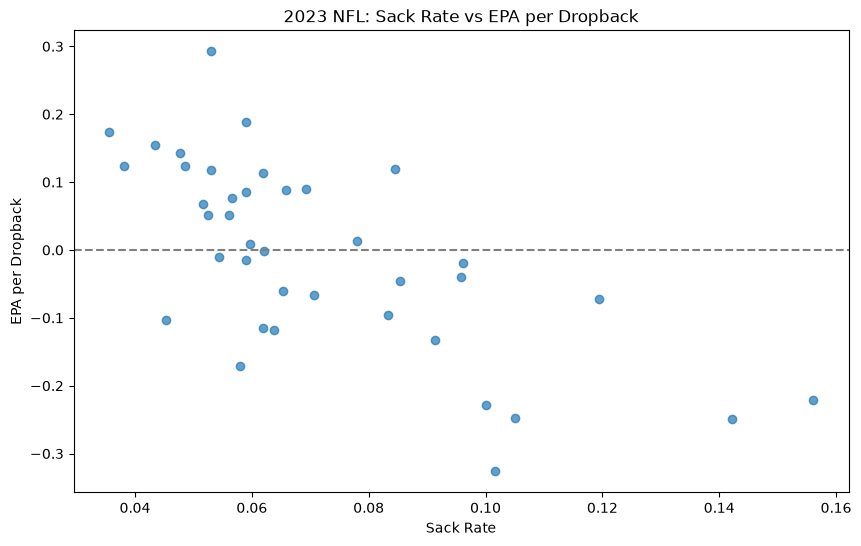

In [13]:
plt.figure(figsize=(10, 6))
plt.scatter(
    qualified_qbs["sack_rate"],
    qualified_qbs["epa_per_dropback"],
    alpha=0.7
)

plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("Sack Rate")
plt.ylabel("EPA per Dropback")
plt.title("2023 NFL: Sack Rate vs EPA per Dropback")

plt.show()

### 6.2 - Calculate the correlation of sack rate and epa per dropback

In [14]:
sack_corr = qualified_qbs[
    "sack_rate"
].corr(qualified_qbs["epa_per_dropback"])

print(f"Correlation: {sack_corr:.3f}")

Correlation: -0.685


### 6.3 - Calculate the correlation of scramble rate and epa per dropback

In [15]:
scramble_corr = qualified_qbs[
    "scramble_rate"
].corr(qualified_qbs["epa_per_dropback"])

print(f"Scramble correlation: {scramble_corr:.3f}")

Scramble correlation: -0.118


### 7 - Compare the EPA of different dropback outcomes

In [16]:
qb_plays["dropback_type"] = np.select(
    [
        qb_plays["sack"] == 1, 
        qb_plays["qb_scramble"] == 1
    ],
    [
        "Sack", 
        "Scramble"
    ], default="Other dropback"
)

epa_by_type = (
    qb_plays
    .groupby("dropback_type")
    .agg(
        plays=("epa", "size"),
        mean_epa=("epa", "mean"),
        median_epa=("epa", "median")
    )
    .reset_index()
)

epa_by_type

,dropback_type,plays,mean_epa,median_epa
0,Other dropback,19264,0.116872,-0.109539
1,Sack,1459,-1.797979,-1.557734
2,Scramble,1096,0.446733,0.250660


### 8 - Interpret the Results and Test the Hypothesis

### 8.1 - What was Discovered
Sack rate: -0.685

This indicates that quarterbacks with higher sack rates generally had lower EPA/dropback during the 2023 season. That is consistent with the hypothesis about negative play avoidance. The strong negative correlation establishes a clear relationship that sacks directly contribute negatively to EPA, however this relationship is mathematical rather than evidence of an independently predictive skill. Additionally, offensive line quality, offensive scheme, and quarterback decision making can all influence sack rate.


Scramble rate: -0.118

This indicates that scrambling more frequently was not strongly associated with higher overall EPA/dropback across the qualified 2023 quarterbacks.

### 8.2 - EPA by dropback type
Scrambles produced more average EPA than other dropbacks, yet quarterbacks who scrambled more frequently did not necessarily have higher overall EPA/dropback. These results aren't contradictory. One measures the average value of individual plays; the other measures a relationship between season level quarterback statistics. For example, a quarterback could generate positive EPA when scrambling but also take too many sacks or make poor passing decisions. Also, the mean EPA of other dropbacks is positive while its median is negative. This suggests the distribution may be influenced by relatively high-value positive plays, although we'd need to inspect its shape to confirm.

### 8.3 - Important Statistical Distinction
The original hypothesis is predictive: $X_{\text{college}} \longrightarrow Y_{\text{future NFL}}$

But the current analysis is descriptive: $X_{\text{NFL 2023}} \longrightarrow Y_{\text{NFL 2023}}$

From what is done so far, its unreliable to establish that college sack avoidance predicts future NFL performance. To test that, eventually historical college QB features, subsequent NFL outcomes, and validation on quarterbacks not used to fit the model are needed.

### 9 - Isolating the Effect of Sacks
A strong negative correlation between sack rate and EPA/dropback has been found. However, because sacks directly reduce EPA, establishing how much of that correlation is simply built into the calculation is essential.

Calculating a second outcome will help: $$EPA/\text{Non-sack DB} = \frac{\sum EPA_{\text{non-sack plays}}}{N_{\text{non-sack dropbacks}}}$$

This second calculation will help us investigate whether quarterbacks who take more sacks also perform worse on plays where they aren't sacked. It won't eliminate confounding or establish causation, but it will remove the direct contribution of sacks from the comparison outcome.


### 9.1 - Calculate non-sack EPA

In [17]:
# Keep dropback that did not end in a sack
non_sack_plays = qb_plays.loc[
    qb_plays["sack"] == 0
].copy()

# Calculate QB performance on non-sack dropbacks
non_sack_stats = (
    non_sack_plays
    .groupby("qb_id", as_index=False)
    .agg(
        non_sack_dropbacks=("epa", "size"),
        non_sack_total_epa=("epa", "sum")
    )
)

non_sack_stats["non_sack_epa_per_db"] = (
    non_sack_stats["non_sack_total_epa"]
    / non_sack_stats["non_sack_dropbacks"]
)

non_sack_stats.head()

,qb_id,non_sack_dropbacks,non_sack_total_epa,non_sack_epa_per_db
0,00-0023459,1,-0.510172,-0.510172
1,00-0026158,253,-3.767114,-0.014890
2,00-0026498,571,122.052667,0.213752
3,00-0026625,42,-7.350968,-0.175023
4,00-0027114,1,2.670900,2.670900


### 9.2 - Merge with Exisiting Quarterback Statistics

In [18]:
qb_comparison = qualified_qbs.merge(
    non_sack_stats[
        ["qb_id", "non_sack_epa_per_db"]
    ],
    on="qb_id",
    how="left"
)

qb_comparison[
    [
        "qb_name",
        "sack_rate",
        "epa_per_dropback",
        "non_sack_epa_per_db"
    ]
].head()

,qb_name,sack_rate,epa_per_dropback,non_sack_epa_per_db
0,J.Flacco,0.045283,-0.103806,-0.014890
1,M.Stafford,0.053068,0.117451,0.213752
2,T.Taylor,0.077982,0.012547,0.133704
3,R.Wilson,0.085389,-0.045210,0.132390
4,K.Cousins,0.051672,0.067098,0.188269


### 9.3 Compare the Correlations

In [19]:
raw_corr = qb_comparison[
    "sack_rate"
].corr(qb_comparison["epa_per_dropback"])

adjusted_corr = qb_comparison[
    "sack_rate"
].corr(qb_comparison["non_sack_epa_per_db"])

print(f"Sack rate vs raw EPA/DB: {raw_corr:.3f}")
print(f"Sack rate vs non-sack EPA/DB: {adjusted_corr:.3f}")

Sack rate vs raw EPA/DB: -0.685
Sack rate vs non-sack EPA/DB: -0.506


The relationship weakened, but it did not disappear.

Initially we found an $r = -0.685$. Since sacks typically generate substantially negative EPA, initial expectations are that quarterbacks with higher sack rates have lower EPA/dropback. However, it's imperative to determine whether the relationship existed beyond the direct EPA penalty of sacks.

After removing sack plays from the outcome: $r = -0.506$. That is still a meaningful negative association. This suggests that quarterbacks who take sacks more frequently also tend to produce less EPA on their non-sack dropbacks. 

There could be several possible explainations, for example:
- Quarterbacks who struggle to process defenses may both take more sacks and make less effective passing decisions.
- Quarterbacks playing behind poor offensive lines may experience more sacks and worse passing conditions.
- Offensive schemes, receiver separation, and defensive competition could influence both metrics.

The important thing right now is that we cannot yet determine which explaination is responsible. A useful mathmatical observations is that we can express a quarterback's overall EPA/dropback as: $$EPA_{\text{overall}} = p_s EPA_{\text{sack}} + (1 - p_s) EPA_{\text{non-sack}}$$

where $p_s$ is the quarterback's sack rate. This is a weighted average of performance on sack and non-sack plays. That decomposition helps explain why sack rate is mechanically related to overall EPA.

### 10 - Investigate Receiver contributions to EPA
Now the next investigation is whether quarterback EPA/dropback is associated with yards gained after the catch (YAC). With this investigation were concerned with scenarios where a quarter throws a short pass and the receiver breaks several tacks to score a touchdown versus scenarios where a quarterback makes a long throw to a covered receiver for a large gain. Before any adjustments are made, exploring the relationship between YAC and EPA is useful.

## 10.1 - Isolate Completed Passes
First, completed passes must be identified, the current `qb_plays` dataset includes sacks, scrambles, incompletions, and completed passes. For this analysis, only completed passes are needed.

In [20]:
# Identify completed passes
completed_passes = qb_plays.loc[
    qb_plays["complete_pass"] == 1
].copy()

print("Completed passes:", len(completed_passes))

completed_passes[
    [
        "qb_name",
        "air_yards",
        "yards_after_catch",
        "yards_gained",
        "epa"
    ]
].head(10)

Completed passes: 12427


,qb_name,air_yards,yards_after_catch,yards_gained,epa
3,S.Howell,6.0,0.0,6.0,0.703308
6,S.Howell,12.0,0.0,12.0,1.173155
7,S.Howell,-4.0,5.0,1.0,-0.515452
9,S.Howell,-3.0,5.0,2.0,-1.430719
13,J.Dobbs,6.0,0.0,6.0,1.648779
15,J.Dobbs,-4.0,1.0,-3.0,-1.215581
19,S.Howell,4.0,2.0,6.0,0.484837
21,S.Howell,2.0,1.0,3.0,1.409476
25,S.Howell,7.0,0.0,7.0,1.590677
30,J.Dobbs,-6.0,5.0,-1.0,-0.925954


### 10.2 - Calculate how much Yardage Comes After the catch
For each completed pass: $$YAC\ Share_i = \frac{YAC_i}{YardsGained_i}$$

However, this ratio becomes difficult to interpret for zero yard and negative yard plays, and it can exceed 100% when a completion is caught behind the line of scrimmage. For the initial analysis, restricting this particular calculation to completed passes gaining positive yardage is a good idea.

In [21]:
positive_completions = completed_passes.loc[
    completed_passes["yards_gained"] > 0
].copy()

positive_completions["yac_share"] = (
    positive_completions["yards_after_catch"]
    / positive_completions["yards_gained"]
)

positive_completions[
    [
        "qb_name",
        "air_yards",
        "yards_after_catch",
        "yac_share",
        "epa"
    ]
].head(10)

,qb_name,air_yards,yards_after_catch,yac_share,epa
3,S.Howell,6.0,0.0,0.000000,0.703308
6,S.Howell,12.0,0.0,0.000000,1.173155
7,S.Howell,-4.0,5.0,5.000000,-0.515452
9,S.Howell,-3.0,5.0,2.500000,-1.430719
13,J.Dobbs,6.0,0.0,0.000000,1.648779
19,S.Howell,4.0,2.0,0.333333,0.484837
21,S.Howell,2.0,1.0,0.333333,1.409476
25,S.Howell,7.0,0.0,0.000000,1.590677
31,J.Dobbs,14.0,17.0,0.548387,2.809702
43,J.Dobbs,3.0,1.0,0.250000,-0.064859


### 10.3 - Aggregate YAC Statistics by Quarterback

In [22]:
qb_yac = (
    completed_passes
    .groupby(["qb_id", "qb_name"], as_index=False)
    .agg(
        completions=("epa", "size"),
        total_yac=("yards_after_catch", "sum"),
        total_rec_yards=("yards_gained", "sum"),
        mean_air_yards=("air_yards", "mean"),
        completion_epa=("epa", "mean")
    )
)

qb_yac["yac_percentage"] = (
    qb_yac["total_yac"]
    / qb_yac["total_rec_yards"]
)

qb_yac.head()

,qb_id,qb_name,completions,total_yac,total_rec_yards,mean_air_yards,completion_epa,yac_percentage
0,00-0026158,J.Flacco,157,808.0,1923.0,7.101911,0.818437,0.420177
1,00-0026498,M.Stafford,351,2102.0,4332.0,6.367521,0.938728,0.485226
2,00-0026625,B.Hoyer,23,80.0,231.0,6.565217,0.906356,0.346320
3,00-0027114,T.Morstead,1,8.0,18.0,10.000000,2.670900,0.444444
4,00-0027948,B.Gabbert,18,118.0,185.0,3.722222,0.688951,0.637838


`yac_percentage` is the share of completed pass receiving yards gained after the catch, rather than the average of individual play level YAC shares.

### 10.4 - Compare YAC Dependence with Quarterback EPA
Merge YAC statisitics with the original QB performance dataset.

In [23]:
qb_yac_comparison = qualified_qbs.merge(
    qb_yac[
        ["qb_id", "completions", "yac_percentage"]
    ],
    on="qb_id",
    how="left"
)

# Correlation between YAC share and overall EPA
yac_corr = qb_yac_comparison[
    "yac_percentage"
].corr(qb_yac_comparison["epa_per_dropback"])

print(f"YAC share vs EPA/DB correlation: {yac_corr:.3f}")

YAC share vs EPA/DB correlation: -0.100


In [24]:
qb_yac_comparison[
    [
        "qb_name",
        "dropbacks",
        "completions",
        "yac_percentage",
        "epa_per_dropback"
    ]
].sort_values(
    "yac_percentage",
    ascending=False
).head(25)

,qb_name,dropbacks,completions,yac_percentage,epa_per_dropback
11,P.Mahomes,839,505,0.589224,0.123978
16,J.Browning,284,171,0.572831,0.119502
27,M.Jones,380,224,0.569811,-0.171561
3,R.Wilson,527,297,0.564495,-0.045210
17,K.Murray,305,176,0.543079,-0.014793
24,J.Burrow,402,244,0.536596,0.008593
34,T.DeVito,237,114,0.529519,-0.220437
29,S.Howell,711,388,0.511657,-0.132700
31,K.Pickett,361,201,0.501449,-0.118622
32,B.Zappe,246,127,0.500786,-0.326412


### 11 - Visualizing YAC and QB Performance
The relationship between YAC percentge and EPA/dropback: $r = -0.100$. This indicates that there's very little linear association between these variables across the qualified quarterbacks in 2023. However, correlation alone doesn't reveal the complete relationship. It's worth while to examine the actual observations, identify outliers, and determine whether other variables might explain differences between quarterbacks.

### 11.1 - Research Question
Do quarterbacks who generate a greater proportion of their passing yards through YAC tend to produce higher EPA/dropback? Visualizing the relationship between YAC percentage and EPA/dropback with a scatterplot will be useful. $X = \text{YAC Percentage}$, $Y = \text{EPA per Dropback}$. Each observation represents one qualified quarterback from the 2023 season.

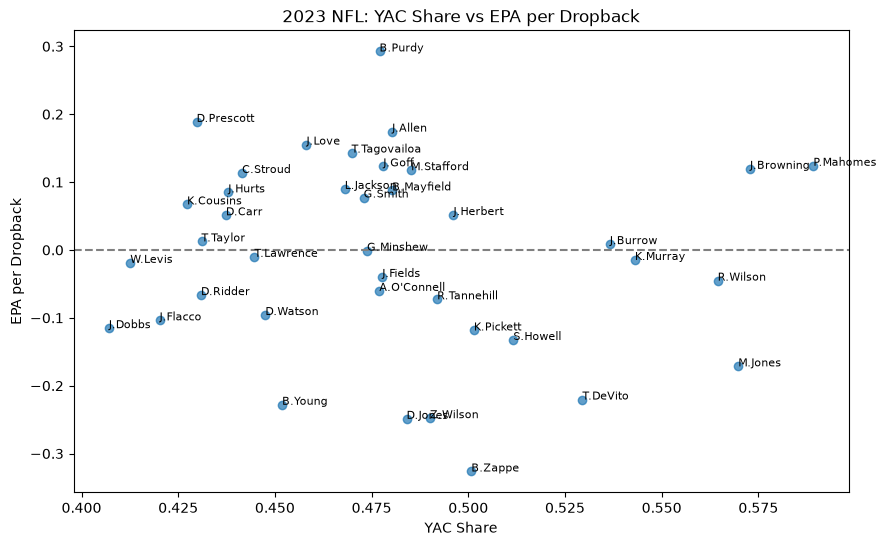

In [25]:
plt.figure(figsize=(10,6))

plt.scatter(
    qb_yac_comparison["yac_percentage"],
    qb_yac_comparison["epa_per_dropback"],
    alpha=0.7
)

for _, row in qb_yac_comparison.iterrows():
    plt.annotate(
        row["qb_name"],
        (
            row["yac_percentage"],
            row["epa_per_dropback"]
        ),
        fontsize=8
    )

plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("YAC Share")
plt.ylabel("EPA per Dropback")
plt.title("2023 NFL: YAC Share vs EPA per Dropback")

plt.show()

### 11.2 - Interpret the Scatterplot
1. There is no obvious linear relationship. Quarterbacks with similar YAC percentages have substantially different EPA/dropback values. For example, around a YAC share of 0.48, we observe quarterbacks producing approximately -0.25 to +0.29 EPA/dropback. That's a substantial difference in efficiency despite relatively similar YAC dependence. 
2. There appears to be a concentration of quarterbacks around 40-50% YAC. Most observations fall in this region, with fewer quarterbacks above 55% YAC. However, that doesn't establish a meaningful statistical cluster on its own.
3. High YAC percentage doesn't guarantee high EPA. On the right side of the graph, quarterbacks with YAC shares above 55% have both positive and negative EPA/dropback values.
4. There are potential outliers worth investigating. The quarterback near 0.48 YAC share and +0.29 EPA/dropback stands out, as do several quarterbacks with EPA/dropback below -0.20.

An important statisitical distinction is that the findings do not demonstrate that YAC has no effect on quarterback performance. They demonstrate that, in this sample, YAC share alone does not explain much of the between quarterback variation in EPA/dropback through a linear relationship. There could still be nonlinear relationships, interacations with other variables, or effects obscured by offensive scheme and personel.

### 11.3 - Identify the Quarterbacks Behind the Observations

In [26]:
qb_yac_comparison[
    [
        "qb_name",
        "yac_percentage",
        "epa_per_dropback",
        "dropbacks"
    ]
].sort_values(
    "epa_per_dropback",
    ascending=False
).head(10)

,qb_name,yac_percentage,epa_per_dropback,dropbacks
30,B.Purdy,0.477048,0.292405,604
8,D.Prescott,0.429762,0.188657,728
15,J.Allen,0.480298,0.174355,732
21,J.Love,0.458162,0.155223,690
20,T.Tagovailoa,0.469832,0.143452,649
11,P.Mahomes,0.589224,0.123978,839
9,J.Goff,0.478012,0.123121,762
16,J.Browning,0.572831,0.119502,284
1,M.Stafford,0.485226,0.117451,603
38,C.Stroud,0.441519,0.113349,613


### 11.4 - Next Experiment: Air Yards Versus YAC
The next question is: Do quarterbacks with higher YAC percentages tend to throw shorter passes? This is useful because it helps to distinguish offensive styles before attempting to adjust quarterback EPA.

In [27]:
qb_air_comparison = qb_yac_comparison.merge(
    qb_yac[["qb_id", "mean_air_yards"]],
    on="qb_id",
    how="left"
)

qb_air_comparison[
    [
        "qb_name",
        "yac_percentage",
        "mean_air_yards",
        "epa_per_dropback"
    ]
].head()

,qb_name,yac_percentage,mean_air_yards,epa_per_dropback
0,J.Flacco,0.420177,7.101911,-0.103806
1,M.Stafford,0.485226,6.367521,0.117451
2,T.Taylor,0.431022,6.577586,0.012547
3,R.Wilson,0.564495,4.494949,-0.045210
4,K.Cousins,0.427284,6.180556,0.067098


In [28]:
may_corr = qb_air_comparison[
    "yac_percentage"
].corr(qb_air_comparison["mean_air_yards"])

print(f"YAC share vs mean air yards correlation: {may_corr:.3f}")

YAC share vs mean air yards correlation: -0.787


### 11.4 Interpreting Air Yards and YAC
The relationship between YAC percentge and mean air yards: $r = -0.787$. This represents a strong linear relationship in the sample. In other words, quarterbacks whose completed passes travel further through the air tend to generate a smaller proportion of their completed passing yards after the catch.

1. Why might this relationship exist? Consider two hypothetical completions: 
- Short completion: 5 air yards, 15 YAC, 20 total yards, YAC share = 75%. 
- Deep completion: 25 air yards, 5 YAC, 30 total yards, YAC share = 16.7%

Notice that deeper completion still generates positive YAC, but YAC accounts for a much smaller percentage of total yards. This reveals an important statistical issue. YAC percentage is a ratio: $$\text{YAC Share} = \frac{\text{Total YAC}}{\text{Total Receiving Yards}}$$, and approximately, for completed passes: $$\text{Receiving Yards} = \text{Air Yards} + \text{YAC}$$. As air yards increase, the denominator of YAC share can increase even if the receiver generates exactly the same number of yards after the catch. Therefore, part of the negative correlation may arise mechanically from how YAC percentage is defined. As such there should be no interpretation of the -0.787 correlation as evidence that throwing deeper necessarily reduces a receiver's ability to generate YAC.

2. Important implication for this study
These features are strongly correlated and may contain overlapping information about offensive passing style. For linear models, that could introduce multicollinearity, making individual coefficient estimates less stable and harder to interpret. It doesn't automatically mean that trashing either variable is a good idea, however understanding what each measures and whether both improve out-of-sample predictions is important. A bigger concern is that our ultimate goal is evaluating quarterback talent, not simply describing offensive style so either feature should be avoided as a direct measure of quarterback ability.

### 11.5 - Seperating YAC Volume from YAC Percentage
Just before, the relationship between YAC percentge and mean air yards was found. However, identifying what happens when YAC percentage is replaced with YAC per completion could help investigate whether the negative relationship is partly driven by the denominator.

The first step is to create the new calculation: $$\text{YAC per Completion}_i = \frac{\text{Total YAC}_i}{\text{Completions}_i}$$. From there we can go onto comparing the correlations and finally interpreting the difference.


In [29]:
qb_yac["yac_per_completion"] = (
    qb_yac["total_yac"]
    / qb_yac["completions"]
)

yac_comp_corr = qb_yac["yac_per_completion"].corr(
    qb_yac["mean_air_yards"]
)

print(f"YAC per completion versus mean air yards correlation: {yac_comp_corr:.3f}")

YAC per completion versus mean air yards correlation: 0.057


In [30]:
qb_air_comparison = qb_air_comparison.drop(
    columns=["yac_per_completion"],
    errors="ignore"
)

qb_air_comparison = qb_air_comparison.merge(
    qb_yac[["qb_id", "yac_per_completion"]],
    on="qb_id",
    how="left",
    validate="one_to_one"
)

The results changed substantially.
- YAC percentage versus mean air yards: $r = -0.787$
- YAC per completion versus mean air yards: $r = 0.057$

The strong negative associate almost disappears. This supports the idea that the original relationship was substantially influenced by how YAC percentage is calculated. It doesn't prove that the denominator accounts for the entire relationship, but it's compelling evidence that caution it warrented for interpreting the original correlation as a football phenomenon.

### 12 - Negative Play Analysis

### 12.1 - Research Question
Do quarterbacks who generate higher EPA per dropback
avoid negative plays more frequently, experience less
severe negative outcomes, or both?

Things to investigate:
- Negative-play frequency
- Average negative-play EPA
- Median negative-play EPA
- Severe negative-play frequency

A negative play is initially defined as a dropback
with EPA < 0. This measures an unfavorable play
outcome, not necessarily a quarterback mistake.

In [31]:
negative_plays = qb_plays[
    qb_plays["epa"] < 0
].copy()

print("Total dropbacks:", len(qb_plays))
print("Negative-EPA dropbacks:", len(negative_plays))

print(
    "Negative-play percentage",
    round(len(negative_plays) / len(qb_plays) * 100, 2)
)

Total dropbacks: 21819
Negative-EPA dropbacks: 12102
Negative-play percentage 55.47


### 12.2 - Quarterback Negative-Play Frequency and Severity
Calculating the following statistics for each quarterback:

1. Negative-play count
2. Average negative-play EPA
3. Median negative-play EPA

These statistics will help distinguish how frequently negative
outcomes occur from how damaging those outcomes tend to be.

In [32]:
qb_negative_stats = (
    negative_plays
    .groupby(["qb_id", "qb_name"], as_index=False)
    .agg(
        negative_plays=("epa", "size"),
        mean_negative_epa=("epa", "mean"),
        median_negative_epa=("epa", "median"),
        total_negative_epa=("epa", "sum")
    )
)

qb_negative_stats.head(10)

,qb_id,qb_name,negative_plays,mean_negative_epa,median_negative_epa,total_negative_epa
0,00-0023459,A.Rodgers,2,-1.015980,-1.015980,-2.031960
1,00-0026158,J.Flacco,153,-1.287955,-0.756267,-197.057157
2,00-0026498,M.Stafford,325,-0.985880,-0.683384,-320.411130
3,00-0026625,B.Hoyer,24,-1.280166,-0.868704,-30.723982
4,00-0027948,B.Gabbert,26,-1.231603,-0.598785,-32.021680
5,00-0027973,A.Dalton,36,-0.774185,-0.584145,-27.870659
6,00-0028118,T.Taylor,123,-0.942987,-0.731526,-115.987372
7,00-0028872,J.Hekker,1,-1.941088,-1.941088,-1.941088
8,00-0028986,C.Keenum,37,-1.185912,-0.817290,-43.878746
9,00-0029263,R.Wilson,299,-1.043682,-0.697424,-312.060981


1. Understanding the results.

Stafford has more negative plays than Wilson, but Wilson's negative plays are slightly more damaging on average. Stafford also had 603 dropbacks to Wilson's 527. Comparing their negative play counts directly without accounting for their different opportunities is a mistake. Using those dropbacks as the denominators:
$$\text{Stafford Negative Rate} = \frac{325}{603} \approx 53.9\%$$
$$\text{Wilson Negative Rate} = \frac{299}{527} \approx 56.7\%$$
Stafford actually has the lower negative play rate. This demonstrates why rates are generally more useful than raw counts when comparing players with different workloads.

2. The mathmatical relationship.

A quarterback's EPA per dropback can be decomposed into two componenets: $$\boxed{\overline{EPA} = p_- \mu_- + (1 - p_-) \mu_{\geq 0}}$$
Where:
- $p_-$: proportion of negative EPA dropbacks.
- $\mu_-$: average EPA on negative plays.
- $\mu_{\geq 0}$: average EPA on nonnegative plays.


### 12.3 - Normalize Negative Plays by Dropbacks

Raw negative-play counts are influenced by playing time. To compare quarterbacks fairly, calculating the proportion of their total dropbacks that produce negative EPA will help. Negative-play rate = Negative plays / Total dropbacks

In [33]:
qb_negative_comparison = qualified_qbs.merge(
    qb_negative_stats[
        [
            "qb_id",
            "negative_plays",
            "mean_negative_epa",
            "median_negative_epa",
            "total_negative_epa"
        ]
    ],
    on="qb_id",
    how="left",
    validate="one_to_one"
)

qb_negative_comparison["negative_play_rate"] = (
    qb_negative_comparison["negative_plays"]
    / qb_negative_comparison["dropbacks"]
)

qb_negative_comparison[
    [
        "qb_name",
        "dropbacks",
        "negative_play_rate",
        "mean_negative_epa",
        "median_negative_epa",
        "epa_per_dropback"
    ]
].sort_values(
    "negative_play_rate",
    ascending=True
).head(15)

,qb_name,dropbacks,negative_play_rate,mean_negative_epa,median_negative_epa,epa_per_dropback
30,B.Purdy,604,0.471854,-1.017559,-0.759479,0.292405
8,D.Prescott,728,0.490385,-1.015633,-0.709815,0.188657
15,J.Allen,732,0.493169,-0.947567,-0.695176,0.174355
9,J.Goff,762,0.503937,-1.052583,-0.697617,0.123121
11,P.Mahomes,839,0.512515,-0.966601,-0.630934,0.123978
13,L.Jackson,636,0.512579,-1.011690,-0.700510,0.089907
20,T.Tagovailoa,649,0.516179,-1.057898,-0.693509,0.143452
6,G.Smith,548,0.516423,-0.980642,-0.742400,0.077232
16,J.Browning,284,0.521127,-1.014977,-0.692383,0.119502
24,J.Burrow,402,0.527363,-0.990826,-0.666127,0.008593


### 12.4 - Decomposing EPA into positive and negative outcomes

Research Question: Do quarterbacks with higher EPA per dropback generate positive outcomes more frequently, produce more valuable positive outcomes, or both? A positive play is defined as a dropback with EPA > 0. Calculating positive-play counts, mean positive EPA, median positive EPA, and total positive EPA.

Measuring positive play production and test whether it helps explain differences between quarterbacks. That's defined: $$p_+ = \frac{\text{Positive-EPA dropbacks}}{\text{Total dropbacks}}$$ $$\mu_+ = \text{Mean EPA on positive-EPA dropbacks}$$
Now to express overall EPA per dropback as: $$\overline{EPA} = p_+ \mu_+ + p_- \mu_-$$
Zero EPA plays contribute nothing to the numerator but remain in the total dropback denominator.



In [34]:
positive_plays = qb_plays[
    qb_plays["epa"] > 0
].copy()

print("Total dropbacks:", len(qb_plays))
print("Positive EPA dropbacks:", len(positive_plays))

print(
    "Positive play percentage:",
    round(len(positive_plays) / len(qb_plays) * 100, 2)
)

Total dropbacks: 21819
Positive EPA dropbacks: 9717
Positive play percentage: 44.53


In [35]:
qb_positive_stats = (
    positive_plays
    .groupby(["qb_id", "qb_name"], as_index=False)
    .agg(
        positive_plays=("epa", "size"),
        mean_positive_epa=("epa", "mean"),
        median_positive_epa=("epa", "median"),
        total_positive_epa=("epa", "sum")
    )
)

qb_positive_stats.head(15)

,qb_id,qb_name,positive_plays,mean_positive_epa,median_positive_epa,total_positive_epa
0,00-0026158,J.Flacco,112,1.513827,1.197115,169.548616
1,00-0026498,M.Stafford,278,1.407316,1.202674,391.233808
2,00-0026625,B.Hoyer,19,1.154906,1.174569,21.943209
3,00-0027114,T.Morstead,1,2.670900,2.670900,2.670900
4,00-0027948,B.Gabbert,14,1.390876,1.223083,19.472265
5,00-0027973,A.Dalton,26,1.294385,1.000413,33.653997
6,00-0028118,T.Taylor,95,1.249712,0.818936,118.722627
7,00-0028986,C.Keenum,22,1.055792,0.727613,23.227417
8,00-0029263,R.Wilson,228,1.264190,0.909910,288.235386
9,00-0029604,K.Cousins,150,1.446433,1.215243,216.964886


### 12.5 - Combine Positive and Negative Outcomes
Research Question: How much of each quarterback's EPA per dropback comes from generating positive outcomes versus absorbing negative outcomes?

In [36]:
qb_positive_comparison = qb_negative_comparison.merge(
    qb_positive_stats[
        [
            "qb_id",
            "positive_plays",
            "mean_positive_epa",
            "median_positive_epa",
            "total_positive_epa"
        ]
    ],
    on="qb_id",
    how="left",
    validate="one_to_one"
)

qb_positive_comparison["positive_play_rate"] = (
    qb_positive_comparison["positive_plays"]
    / qb_positive_comparison["dropbacks"]
)

qb_positive_comparison["reconstructed_epa_per_db"] = (
    (
        qb_positive_comparison["positive_play_rate"]
        * qb_positive_comparison["mean_positive_epa"]
    ) 
    +
    (
        qb_positive_comparison["negative_play_rate"]
        * qb_positive_comparison["mean_negative_epa"]
    )
)

qb_positive_comparison["reconstruction_error"] = (
    qb_positive_comparison["reconstructed_epa_per_db"]
    - qb_positive_comparison["epa_per_dropback"]
)

print(
    "Maximum absolute reconstruction error:",
    qb_positive_comparison["reconstruction_error"].abs().max()
)

qb_positive_comparison[
    [
        "qb_name",
        "dropbacks",
        "negative_play_rate",
        "mean_negative_epa",
        "median_negative_epa",
        "positive_play_rate",
        "mean_positive_epa",
        "median_positive_epa",
        "reconstructed_epa_per_db",
        "epa_per_dropback"
    ]
].sort_values(
    "reconstructed_epa_per_db",
    ascending=False
).head(15)

Maximum absolute reconstruction error: 1.6653345369377348e-16


,qb_name,dropbacks,negative_play_rate,mean_negative_epa,median_negative_epa,positive_play_rate,mean_positive_epa,median_positive_epa,reconstructed_epa_per_db,epa_per_dropback
30,B.Purdy,604,0.471854,-1.017559,-0.759479,0.528146,1.462749,1.207524,0.292405,0.292405
8,D.Prescott,728,0.490385,-1.015633,-0.709815,0.509615,1.347502,1.058114,0.188657,0.188657
15,J.Allen,732,0.493169,-0.947567,-0.695176,0.506831,1.266037,0.993921,0.174355,0.174355
21,J.Love,690,0.533333,-0.932892,-0.643109,0.466667,1.398784,1.110125,0.155223,0.155223
20,T.Tagovailoa,649,0.516179,-1.057898,-0.693509,0.483821,1.425147,1.213350,0.143452,0.143452
11,P.Mahomes,839,0.512515,-0.966601,-0.630934,0.487485,1.270553,1.058976,0.123978,0.123978
9,J.Goff,762,0.503937,-1.052583,-0.697617,0.496063,1.317488,1.127596,0.123121,0.123121
16,J.Browning,284,0.521127,-1.014977,-0.692383,0.478873,1.354082,1.084545,0.119502,0.119502
1,M.Stafford,603,0.538972,-0.985880,-0.683384,0.461028,1.407316,1.202674,0.117451,0.117451
38,C.Stroud,613,0.538336,-1.000788,-0.751908,0.461664,1.412520,1.218547,0.113349,0.113349


Maximum reconstruction error: $1.67 \times 10^{-16}$
The reconstructed EPA/dropback matches the original values to floating point precision. This confirms the relationship: $$\overline{EPA} = p_+\mu_+ + p_-\mu_-$$
where $p_+$ and $p_-$ are the proportions of positive and negative plays, and $\mu_+$ and $\mu_-$ are their respective average EPA values.

Example:
- Brock Purdy, Positive play rate: 52.81%, Mean positive EPA: +1.463, Overall EPA/DB: +0.292
- Jordan Love, Positive play rate: 46.67%, Mean positive EPA: +1.398, Overall EPA/DB: +0.155
- Patrick Mahomes, Positive play rate: 48.75%, Mean positive EPA: +1.271, Overall EPA/DB: 0.124

Notice that Jordan Love had a lower positive play rate than Mahomes, yet a higher overall EPA/dropback. That demonstrates why it's irresponsible to judge quarterback effectiveness using positive play frequency alone. One critical distinction: this reconstruction is a mathmatical identity, not a predictive model. It's possible to explain how the observed EPA average is composed, but it's not a reliable explaination for why quarterbacks produce these outcomes.


### 12.6 - Measuring game to game consistency
Calculating EPA per dropback for each quarterback in each game during the 2023 NFL season.

Research question:
Do quarterbacks with higher average EPA/dropback also exhibit lower game-to-game variability?

In [37]:
qb_game_stats = (
    qb_plays
    .groupby(["qb_id", "qb_name", "game_id"], as_index=False)
    .agg(
        game_dropbacks=("epa", "size"),
        game_total_epa=("epa", "sum"),
        game_mean_epa=("epa", "mean")
    )
)

qb_game_stats.head(10)

,qb_id,qb_name,game_id,game_dropbacks,game_total_epa,game_mean_epa
0,00-0023459,A.Rodgers,2023_01_BUF_NYJ,2,-2.031960,-1.015980
1,00-0026158,J.Flacco,2023_13_CLE_LA,46,-7.791564,-0.169382
2,00-0026158,J.Flacco,2023_14_JAX_CLE,46,-7.339273,-0.159549
3,00-0026158,J.Flacco,2023_15_CHI_CLE,48,-17.392163,-0.362337
4,00-0026158,J.Flacco,2023_16_CLE_HOU,43,20.085988,0.467116
5,00-0026158,J.Flacco,2023_17_NYJ_CLE,30,1.736629,0.057888
6,00-0026158,J.Flacco,2023_19_CLE_HOU,52,-16.808159,-0.323234
7,00-0026498,M.Stafford,2023_01_LA_SEA,39,21.533918,0.552152
8,00-0026498,M.Stafford,2023_02_SF_LA,59,-5.869871,-0.099489
9,00-0026498,M.Stafford,2023_03_LA_CIN,40,-5.875214,-0.146880


### 12.7 - Filtering low volume games
Game-level EPA estimates based on very few dropbacks may be unstable.

Before calculating quarterback consistency, an examination of the distribution of dropbacks per game and an evaluation of the impact of excluding low-volume games is useful.

In [38]:
qb_game_stats["game_dropbacks"].describe()

count    723.000000
mean      30.178423
std       15.391924
min        1.000000
25%       24.000000
50%       34.000000
75%       41.000000
max       70.000000
Name: game_dropbacks, dtype: float64

In [39]:
minimum_dropbacks = 20

low_volume_games = qb_game_stats[
    qb_game_stats["game_dropbacks"] < minimum_dropbacks
]

print("Total QB-game observations:", len(qb_game_stats))
print("Low-volume observations:", len(low_volume_games))

Total QB-game observations: 723
Low-volume observations: 156


A few observations:
- Median = 34: Half of the QB game observations contain 34 of fewer dropbacks, and half contain 34 or more.
- Minimum = 1: Some game averages are calculated from a single dropback, making them particularly unstable.
- 156 low volume observations: Excluding them removes approximately one-fifth of the QB game observations.

That last result matters. Removing a substantial portion of the observations can cause a big effect so a sensitivity analysis using alternative thresholds, such as 10, 20, and 30 dropbacks should be performed. Also those 156 observations may not be randomly distributed. Backup quarterbacks, injured starters, and quarterbacks who were benched could be disproportionately affected. This creates a potential selection bias: the filtered sample may represent quarterbacks who remained on the field rather than all quarterbacks who participated. For now, proceeding with 20 dropback is preferable for the exploratory threshold.

### 12.8 - Measuring Game-to-Game Consistency

Excluding quarterback-game observations with fewer than 20 dropbacks before calculating game-level EPA variability. This threshold is provisional and will be evaluated through sensitivity analysis.
The sample standard deviation is: $$s_i = \sqrt{\frac{1}{n_i - 1} \sum_{j=1}^{n_i} (EPA_{ij} - \overline{EPA_i})^2}$$
Where:
- $n_i$ = number of qualifying games for quarterback $i$
- $EPA_{ij}$ = quarterback $i$'s EPA/dropback in game $j$
- $\overline{EPA_i}$ = average of his qualifying game-level EPA/dropback values
- $s_i$ = standard deviation of those game-level values
A smaller $s_i$ means his game-level EPA/dropback is more tightly concentrated around his average. It does not necessarily mean he is a better quarterback.

In [40]:
qualified_games = qb_game_stats[
    qb_game_stats["game_dropbacks"] >= minimum_dropbacks
].copy()

print("Qualified QB game observations:", len(qualified_games))

qualified_games.head()

Qualified QB game observations: 567


,qb_id,qb_name,game_id,game_dropbacks,game_total_epa,game_mean_epa
1,00-0026158,J.Flacco,2023_13_CLE_LA,46,-7.791564,-0.169382
2,00-0026158,J.Flacco,2023_14_JAX_CLE,46,-7.339273,-0.159549
3,00-0026158,J.Flacco,2023_15_CHI_CLE,48,-17.392163,-0.362337
4,00-0026158,J.Flacco,2023_16_CLE_HOU,43,20.085988,0.467116
5,00-0026158,J.Flacco,2023_17_NYJ_CLE,30,1.736629,0.057888


In [41]:
qb_consistency = (
    qualified_games
    .groupby(["qb_id", "qb_name"], as_index=False)
    .agg(
        games=("game_id", "size"),
        mean_game_epa=("game_mean_epa", "mean"),
        std_game_epa=("game_mean_epa", "std")
    )
)

qb_consistency.head(10)

,qb_id,qb_name,games,mean_game_epa,std_game_epa
0,00-0026158,J.Flacco,6,-0.081583,0.307092
1,00-0026498,M.Stafford,16,0.116620,0.248499
2,00-0026625,B.Hoyer,1,-0.410092,NaN
3,00-0027948,B.Gabbert,1,-0.166953,NaN
4,00-0027973,A.Dalton,1,0.093280,NaN
5,00-0028118,T.Taylor,4,0.066159,0.127877
6,00-0028986,C.Keenum,2,-0.485420,0.594598
7,00-0029263,R.Wilson,15,-0.046003,0.259815
8,00-0029604,K.Cousins,8,0.040175,0.334347
9,00-0029701,R.Tannehill,8,-0.030948,0.267602


### 12.8 - Review Results
567 qualifying QB game observations remain.
Something to consider: Tyrod Taylor has a lower standard deviation, suggesting more consistent game level EPA across the games included. However, he only has four qualifying games compared with Stafford's sixteen. Four observations provide a much less reliable estimate of a quarterback's underlying game-to-game variability than sixteen observations. This introduces another problem: the number of games used to estimate consistency matters. Also, the NaN values for quarterbacks with one qualifying game are expected. Pandas uses the sample standard deviation, which requires at least two observations.

### 12.9 - Establish a minimum number of games
To reduce instability in game-to-game consistency estimates, eight qualifying games is required. This ensures that the standard deviation estimates are based on multiple observations, although the estimates may still contain substantial sampling uncertainty. That leaves the analysis with two conditions: $$\text{Qualifies} = \begin{cases} 1 & \text{if at least 8 games have 20+ dropbacks each} \\ 0 & \text{otherwise} \end{cases}$$
Eight games is a provisional research decision, not a statistical guarantee of reliability, later an evaluation of alternative thresholds and how they affect the results is recommended.

In [42]:
minimum_games = 8

qualified_consistency = qb_consistency[
    qb_consistency["games"] >= minimum_games
].copy()

print("Quarterbacks remaining:", len(qualified_consistency))

qualified_consistency.head(10)

Quarterbacks remaining: 33


,qb_id,qb_name,games,mean_game_epa,std_game_epa
1,00-0026498,M.Stafford,16,0.116620,0.248499
7,00-0029263,R.Wilson,15,-0.046003,0.259815
8,00-0029604,K.Cousins,8,0.040175,0.334347
9,00-0029701,R.Tannehill,8,-0.030948,0.267602
10,00-0030565,G.Smith,15,0.057332,0.269065
11,00-0031280,D.Carr,17,0.074823,0.254847
19,00-0033077,D.Prescott,18,0.193449,0.269532
20,00-0033106,J.Goff,20,0.141484,0.213188
25,00-0033873,P.Mahomes,20,0.139427,0.242720
27,00-0033949,J.Dobbs,13,-0.116776,0.313222


In [43]:
qualified_consistency[
    ["qb_name", "games", "mean_game_epa", "std_game_epa"]
].sort_values(
    "std_game_epa",
    ascending=True
).head(15)

,qb_name,games,mean_game_epa,std_game_epa
39,G.Minshew,14,0.031104,0.180754
64,W.Levis,8,0.029918,0.189468
52,Z.Wilson,11,-0.227383,0.212348
20,J.Goff,20,0.141484,0.213188
35,J.Browning,8,0.118292,0.226793
32,J.Allen,18,0.185248,0.236023
46,J.Hurts,17,0.113713,0.236058
25,P.Mahomes,20,0.139427,0.242720
1,M.Stafford,16,0.116620,0.248499
57,D.Ridder,12,-0.023250,0.249793


### 12.10 - Interpret the Consistency Rankings
1. Consistency and performance are different dimensions. Zach Wilson has a relatively low standard deviation, but his mean games EPA/dropback is substantially negative. Josh Allen has a somewhat higher standard deviation and much stronger average performance.
2. Consistency doesn't establish talent. Jared Goff's performance might reflect some combination of quarterback ability, offensive scheme, pass protection, receiver performance, and opponent strength. It's impossible to isolate those contributions from these statistics.
3. Consistency may not be stable across seasons. A quarterback could be consistent in 2023 and highly variable in 2024. If so, consistency might reflect temporary circumstances rather than a persistent quarterback characteristic. This is something to test eventually.

### 12.11 - Visualize performance versus consistency
The two variables that describe different aspects of quarterback performance:
- `mean_game_epa`: average performance across qualifying games.
- `std_game_epa`: variation in performance across those games.
Rather than ranking quarterbacks on one metric, both of these variables can be visualized simultaneously.

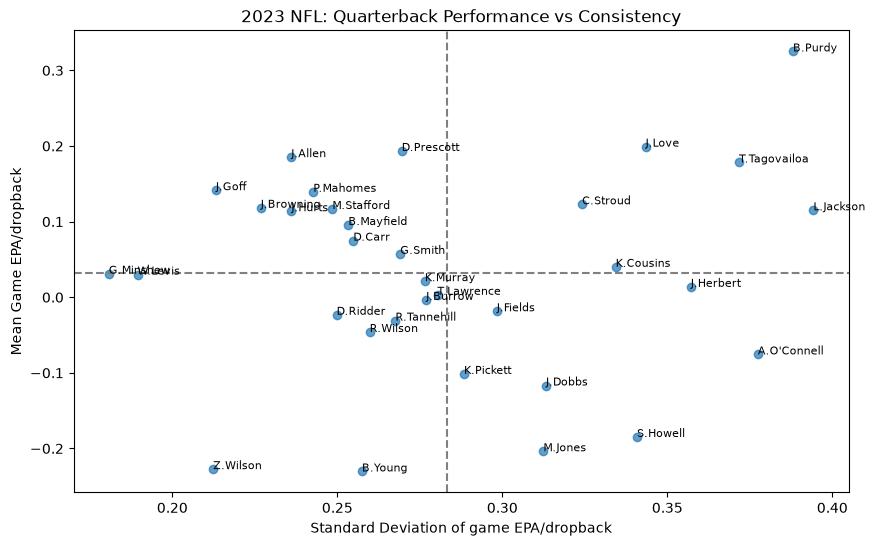

In [44]:
plt.figure(figsize=(10,6))

plt.scatter(
    qualified_consistency["std_game_epa"],
    qualified_consistency["mean_game_epa"],
    alpha=0.7
)

for _, row in qualified_consistency.iterrows():
    plt.annotate(
        row["qb_name"],
        (
            row["std_game_epa"],
            row["mean_game_epa"]
        ),
        fontsize=8
    )

plt.axhline(
    qualified_consistency["mean_game_epa"].mean(), 
    color="gray", 
    linestyle="--")

plt.axvline(
    qualified_consistency["std_game_epa"].mean(), 
    color="gray", 
    linestyle="--")

plt.xlabel("Standard Deviation of game EPA/dropback")
plt.ylabel("Mean Game EPA/dropback")
plt.title("2023 NFL: Quarterback Performance vs Consistency")

plt.show()

### 12.12 - What Does the Scatterplot Say?
- Brock Purdy, Mean game EPA/DB: 0.33, Standard Deviation: 0.39, Interpretation: Very high average performance, high variability
- Josh Allen, Mean game EPA/DB: 0.19, Standard Deviation: 0.24, Interpretation: High average performance, relatively low variability
- Jared Goff, Mean game EPA/DB: 0.14, Standard Deviation: 0.21, Interpretation: Strong performance, relatively low variability
- Zach Wilson, Mean game EPA/DB: 0.23, Standard Deviation: 0.21, Interpretation: Consistently poor observed performance
- C.J. Stroud, Mean game EPA/DB: 0.12, Standard Deviation: 0.32, Interpretation: Positive average performance, higher variability

Brock Purdy has the highest average game EPA/dropback in the sample, but also one of the highest standard deviations. If the ranking was simply by quarterback consistency, one of the highest performing quarterbacks would have been penalized. This illustrates why low variability alone isn't inherently desirable. It's also important to note that while these are valid descriptive reference points, they represent the unweighted averages across quarterbacks, not league-wide averages weighted by dropbacks. Also because this data includes playoff games, the number of games differs between quarterbacks. Neither issue invalidates the visualization, both matter when interpreting it.

### 12.13 - Next Experiement: Is Consistency Predictive?
Hypothesis 1 - Average performance matter more.

Quarterbacks with higher EPA/dropback in one season tend to have higher EPA/dropback in the following season, regardless of their game-togame variability

Hypothesis 2 - Consistency adds predictive information

After accounoting for average EPA/dropback, game-to-game consistency helps predict next-season performance. Eventually two regression models will be compared: 
$$\begin{aligned}
\text{Model A:} \quad EPA_{t+1} &= \beta_0 + \beta_1 EPA_t + \epsilon \\[1ex]
\text{Model B:} \quad EPA_{t+1} &= \beta_0 + \beta_1 EPA_t + \beta_2 SD_t + \epsilon
\end{aligned}$$
Here, $SD_t$ is the standard deviation of game level EPA/dropback during season $t$. If Model B consistently predicts future preformance better than Model A on unseen seasons, then there will be evidence that consistency adds useful perdictive information. But before fitting either model, observations from multiple seasons are needed. The current notebook only analyzes 2023. Additionally, there's a need to handle quarterbacks who don't play enough the following year, simply excluding them automatically could bias the results.

### 13 - Expanding NFL Dataset Across Multiple Seasons
Until now, the analysis has been quarterback performance using 2023 NFL data. With that data theres several metrics identified to be useful features
- EPA per dropback
- Positive and Negative play rates
- Average severity of positive and negative plays
- YAC share and passing depth
- Game-to-game EPA consistency
The next goal is to examine how these metrics behave across multiple seasons, rather than within a single season.

### 13.1 - Research Question
Research Question: Are quarterback performance and consistency stable across NFL seasons, and does game-to-game consistency help predict future performance beyond average EPA/dropback?

This introduces an important concept: temporal stability. A metric is temporally stable when quarterbacks tend to maintain similar values across different periods. For example, a quarterback might consistently have a low pressure-to-sack rate across seasons, even when his overall EPA/dropback fluctuates. That could suggest the metric captures something more persistent about his playing style or decision-making. However, there is still a need to investigate context and whether it predicts future performance.

### 13.2 - Understand Structure of the New Dataset
The existing `qb_game_stats` DataFrame contains one observation per quarterback per game. For the next stage, a new dataset will be created containing one observation per quarterback per season.

Conceptually:
- QB: QB A, Season: 2021, EPA/DB: 0.12, SD game EPA: 0.18, Games: 16
- QB: QB A, Season: 2022, EPA/DB: 0.15, SD game EPA: 0.20, Games: 17 
- QB: QB A, Season: 2023, EPA/DB: 0.08, SD game EPA: 0.38, Games: 15 
- QB: QB A, Season: 2024, EPA/DB: 0.17, SD game EPA: 0.19, Games: 17

Each row represents a quarterback season observation. This structure will eventually help construct predictors from season $t$ and targets from season $t+1$. For instance, a quarterback's 2022 performance could be used to predict his 2023 performance. One important methodological decision: we'll keep the original game level data as well. That shouldn't be discarded as it has the more granular observations due to its aggregation.

In [45]:
seasons = list(range(2018, 2026))
print(seasons)

[2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


### 13.4 - Load Multiple Seasons of NFL Play-by-Play Data
Using `nfl_data_py` package still, `seasons` is the list of seasons to analyze, and `pbp_multi` will contain the play-by-play observation from all eight seasons. The `downcast=True` argument helps reduce memory consumption by using smaller numerical data types where possible.

In [46]:
pbp_multi = nfl.load_pbp(seasons).to_pandas()
print(pbp_multi["season"].value_counts().sort_index())
print(pbp_multi.shape)

season
2018    47109
2019    47260
2020    47705
2021    49922
2022    49434
2023    49665
2024    49492
2025    48771
Name: count, dtype: int64
(389358, 372)


### 13.5 - Two Important Statistical Considerations
1. Sample size reliability

Image these hypothetical results:
- QB Season: QB A, 2023; Dropbacks: 35; EPA/dropback: +0.30
- QB Season: QB A, 2024; Dropbacks: 580; EPA/dropback: +0.12
- QB Season: QB A, 2025; Dropbacks: 610; EPA/dropback: +0.15

Even though 2023 has the highest EPA/dropback, it is based on only 25 dropbacks. That estimate is much more sensitive to a few unusually good or bad plays. We can eventually address this through minimum sample thresholds, weighting observations by dropbacks, and statistical shrinkage.

2.  Differences in the NFL environment

Offensive performance can vary across seasons because of league wide changes in defensive strategies, passing efficiency, rules, and other factors. One technique to explore is season-adjusted EPA:
$$\text{Adjusted EPA}_{i,t} = \text{EPA/DB}_{i,t} - \overline{\text{EPA/DB}_t}$$
Where:
- $i$ represents a quarterback.
- $t$ represents a season.
- $\overline{\text{EPA/DB}_t}$ represents league-average EPA per dropback for that season.

This shows how a quarterback performed relative to the league environment in that particular year. However, season adjustment alone doesn't isolate the effects of offensive-line quality, receivers, coaching, or defensive opponents.

### 13.5 - Construct Multi Season Quarterback Dataset
Currently each row in the dataset represents an individual play. Each row must represent a quarterback's performance during one NFL season.

In [47]:
columns_to_check = [
    "season",
    "game_id",
    "posteam",
    "passer_player_id",
    "passer_player_name",
    "rusher_player_id",
    "rusher_player_name",
    "qb_dropback",
    "qb_scramble",
    "sack",
    "epa",
    "play_type"
]

for col in columns_to_check:
    print(f"{col}: {col in pbp_multi.columns}")

season: True
game_id: True
posteam: True
passer_player_id: True
passer_player_name: True
rusher_player_id: True
rusher_player_name: True
qb_dropback: True
qb_scramble: True
sack: True
epa: True
play_type: True


In [48]:
pbp_multi["qb_dropback"].value_counts(dropna=False)

qb_dropback
0.0    208298
1.0    169639
NaN     11421
Name: count, dtype: int64

### 13.6 - Filter Multi Season Dataset
The 11,421 observations of the missing dropback indicator aren't necessarily bad data. They may correspond to plays for which the indicator is not applicable. To filter the dataset, isolating the 169,639 dropbacks is necessary. Verifying that scrambles and sacks are included is imperative. These checks matter for different reasons:
- Scrambles: Confirm they're included.
- Sacks: Important negative outcomes that must remain in the analysis.
- Missing passer IDs: Need to attribute each dropback to the correct quarterback.
- Missing EPA: Need to identify plays that cannot contribute to the EPA calculations.

Before aggregating the data into QB season observations, the calculations must be reliable.

In [49]:
qb_plays_multi = pbp_multi[
    pbp_multi["qb_dropback"] == 1
].copy()

print("Total QB dropbacks:", len(qb_plays_multi))
print("Seasons:", sorted(qb_plays_multi["season"].unique()))

Total QB dropbacks: 169639
Seasons: [np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


In [50]:
print("Total dropbacks:", len(qb_plays_multi))

print(
    "Scrambles:",
    (qb_plays_multi["qb_scramble"] == 1).sum()
)

print(
    "Sacks:",
    (qb_plays_multi["sack"] == 1).sum()
)

print(
    "Missing passer IDs:",
    qb_plays_multi["passer_player_id"].isna().sum()
)

print(
    "Missing EPA:",
    qb_plays_multi["epa"].isna().sum()
)

Total dropbacks: 169639
Scrambles: 7855
Sacks: 10722
Missing passer IDs: 7851
Missing EPA: 1


### 13.7 - Investigate Missing Quarterback IDs
The most interesting result from the multi seasons checks is the 7,851 missing passer IDs, which is remarkably claose to the 7,855 scrambles. That suggests a possible explanation: on scramble plays, the quarterback may be recorded as the rusher rather than the passer. However testing it would be safer than assuming so.

In [51]:
missing_passer = qb_plays_multi[
    qb_plays_multi["passer_player_id"].isna()
].copy()

print("Dropback with missing passer ID:", len(missing_passer))

print(
    "Scrambles among missing passer IDs:",
    (missing_passer["qb_scramble"] == 1).sum()
)

print(
    "Sacks among missing passer IDs:",
    (missing_passer["sack"] == 1).sum()
)

missing_passer[
    [
        "season",
        "game_id",
        "passer_player_name",
        "rusher_player_name",
        "qb_scramble",
        "sack",
        "epa"
    ]
].head(15)

Dropback with missing passer ID: 7851
Scrambles among missing passer IDs: 7851
Sacks among missing passer IDs: 0


,season,game_id,passer_player_name,rusher_player_name,qb_scramble,sack,epa
19,2018,2018_01_ATL_PHI,NaN,M.Ryan,1.0,0.0,1.519189
62,2018,2018_01_ATL_PHI,NaN,M.Ryan,1.0,0.0,-0.580400
271,2018,2018_01_BUF_BAL,NaN,N.Peterman,1.0,0.0,-0.816358
311,2018,2018_01_BUF_BAL,NaN,L.Jackson,1.0,0.0,-0.521428
314,2018,2018_01_BUF_BAL,NaN,J.Allen,1.0,0.0,0.805449
320,2018,2018_01_BUF_BAL,NaN,J.Allen,1.0,0.0,1.290516
397,2018,2018_01_CHI_GB,NaN,M.Trubisky,1.0,0.0,0.063451
407,2018,2018_01_CHI_GB,NaN,A.Rodgers,1.0,0.0,0.301640
436,2018,2018_01_CHI_GB,NaN,M.Trubisky,1.0,0.0,-0.415843
492,2018,2018_01_CHI_GB,NaN,M.Trubisky,1.0,0.0,-0.038091


### 13.8 - Correctly Attribute Scrambles to Quarterbacks
The investigation confirms:

| Finding | Result |
| :--- | :--- |
| Dropback with missing passer IDs | 7851 |
| Scrambles among those missing IDs | 7851 |
| Sacks among those missing IDs | 0 |

This says every missing passer ID corresponds to a scramble in our dataset.

Understanding EPA per dropback. For the analysis:
$$\text{EPA/Dropback}_i = \frac{\sum_{j=1}^{N_i} \text{EPA}_{ij}}{N_i}$$
where $N_i$ includes:
- Pass attempts
- Sacks
- Quarterback scrambles

It excludes designed quarterback runs, which will be analyzed seperately. A quarterback who scrambles for 15 yards and gains positive EPA receives credit for that play, just as they would for a successful pass. This matters because scrambles would change both the numerator and denominator of the EPA/dropback calculation. The resulting bias depends on whether the quarterback's scramble EPA is higher or lower than their EPA on other dropbacks.

Instead of relying exclusively on `passer_player_id`, new column is created that assigns scrambles to the rushing quarterback. This will give a unified identifier for the quarterback responsible for each dropback. It also uses the same approach for quarterback names, but `qb_id` will be the primary grouping key because names are not necessarily unique. In the next step there should be zero missing quarterback identifiers while retaining all 7855 scrambles and 10722 sacks. That leaves the analysis with one missing EPA value to investigate before calculating the final QB season statistics. Finally, in the last step theres a need to investigate the missing EPA observation and evaluate whether to exclude it from EPA calculations.

In [52]:
qb_plays_multi["qb_id"] = (
    qb_plays_multi["passer_player_id"]
    .fillna(qb_plays_multi["rusher_player_id"])
)

qb_plays_multi["qb_name"] = (
    qb_plays_multi["passer_player_name"]
    .fillna(qb_plays_multi["rusher_player_name"])
)

In [53]:
print(
    "Missing QB IDs:",
    qb_plays_multi["qb_id"].isna().sum()
)

print(
    "Missing QB names:",
    qb_plays_multi["qb_name"].isna().sum()
)

print(
    "Total dropbacks:",
    len(qb_plays_multi)
)

print(
    "Scrambles retained:",
    (qb_plays_multi["qb_scramble"] == 1).sum()
)

print(
    "Sack retained:",
    (qb_plays_multi["sack"] == 1).sum()
)

Missing QB IDs: 0
Missing QB names: 0
Total dropbacks: 169639
Scrambles retained: 7855
Sack retained: 10722


In [54]:
qb_plays_multi.loc[
    qb_plays_multi["epa"].isna(),
    [
        "season",
        "game_id",
        "qb_name",
        "qb_scramble",
        "sack",
        "play_type",
        "epa"
    ]
]

,season,game_id,qb_name,qb_scramble,sack,play_type,epa
49421,2019,2019_01_PIT_NE,B.Roethlisberger,0.0,0.0,pass,NaN


### 13.10 - Finish the Multi Season Data Cleaning

The latest validation results: 
| Validation | Result |
| :--- | :--- |
| Missing quarterback IDs | 0 |
| Missing quarterback names | 0 |
| Total dropbacks | 169,639 |
| Scrambles retained | 7,855 |
| Sacks retained | 10,722 |

The one missing EPA observation was identified as:
- Quarterback: Ben Roethlisberger
- Season: 2019
- Game: Pittsburgh vs. New England, Week 1
- Play type: Pass
- EPA: Missing

There is no basis for estimating the EPA of that particular play from the information shown. Rather than assigning it zero, excluding it from the calculations requiring EPA is better.

The first step to finish part 13 is to create the clean analysis dataset. Next is to construct quarterback season observations with one observation per quarterback per season rather than one observation per play. Mathmatically:
$$\text{EPA/DB}_{i,t} = \frac{\sum_{j=1}^{N_{i,t}} \text{EPA}_{i,t,j}}{N_{i,t}}$$
where $i$ represents a quarterback and $t$ represents an NFL season.

Finally, calculating the additional rates is necessary so normalizing raw sack and scramble totals will help for comparison. The sack rate is not pressure-to-sack conversion rate.


In [55]:
qb_plays_clean = qb_plays_multi.dropna(
    subset=["qb_id", "epa"]
).copy()

print("Original dropback:", len(qb_plays_multi))
print("Clean dropbacks:", len(qb_plays_clean))
print("Observations removed:", len(qb_plays_multi) - len(qb_plays_clean))

Original dropback: 169639
Clean dropbacks: 169638
Observations removed: 1


In [56]:
qb_season_stats = (
    qb_plays_clean
    .groupby(
        ["season", "qb_id", "qb_name"],
        as_index=False
    )
    .agg(
        dropbacks=("epa", "size"),
        total_epa=("epa", "sum"),
        epa_per_dropback=("epa", "mean"),
        scrambles=("qb_scramble", "sum"),
        sacks=("sack", "sum")
    )
)

qb_season_stats.head(10)

,season,qb_id,qb_name,dropbacks,total_epa,epa_per_dropback,scrambles,sacks
0,2018,00-0019596,T.Brady,721,112.801873,0.156452,5.0,22.0
1,2018,00-0020531,D.Brees,593,155.444491,0.262132,4.0,21.0
2,2018,00-0021206,J.McCown,121,-29.596209,-0.244597,5.0,7.0
3,2018,00-0022787,M.Schaub,7,-2.436508,-0.348073,0.0,0.0
4,2018,00-0022803,E.Manning,631,22.877588,0.036256,4.0,47.0
5,2018,00-0022921,L.Fitzgerald,1,3.088043,3.088043,0.0,0.0
6,2018,00-0022924,B.Roethlisberger,713,135.582294,0.190157,12.0,24.0
7,2018,00-0022942,P.Rivers,643,129.665531,0.201657,7.0,35.0
8,2018,00-0023436,A.Smith,370,-8.620847,-0.023300,21.0,22.0
9,2018,00-0023459,A.Rodgers,680,76.739856,0.112853,33.0,49.0


In [57]:
qb_season_stats["scramble_rate"] = (
    qb_season_stats["scrambles"]
    / qb_season_stats["dropbacks"]
)

qb_season_stats["sack_rate"] = (
    qb_season_stats["sacks"]
    / qb_season_stats["dropbacks"]
)

qb_season_stats[
    [
        "season",
        "qb_name",
        "dropbacks",
        "epa_per_dropback",
        "scramble_rate",
        "sack_rate"
    ]
].head(15)

,season,qb_name,dropbacks,epa_per_dropback,scramble_rate,sack_rate
0,2018,T.Brady,721,0.156452,0.006935,0.030513
1,2018,D.Brees,593,0.262132,0.006745,0.035413
2,2018,J.McCown,121,-0.244597,0.041322,0.057851
3,2018,M.Schaub,7,-0.348073,0.000000,0.000000
4,2018,E.Manning,631,0.036256,0.006339,0.074485
5,2018,L.Fitzgerald,1,3.088043,0.000000,0.000000
6,2018,B.Roethlisberger,713,0.190157,0.016830,0.033661
7,2018,P.Rivers,643,0.201657,0.010886,0.054432
8,2018,A.Smith,370,-0.023300,0.056757,0.059459
9,2018,A.Rodgers,680,0.112853,0.048529,0.072059


### 13.11 - Examine Quarterback Season Sample Sizes
Examining the distribution of dropbacks to decide which quarterback seasons qualify for the longitudinal analysis. The first step is to summarize season level dropbacks displaying the mean, median, standard deviation, minimum, maximum, and selected percentiles. Then, examining how many seasons meet different thresholds is the next step. This step is a sensitivity analysis: rather than arbitrarily selecting 200 or 300 dropbacks, the purpose is to examine how different thresholds change the sample. Different threshold could be used for different analyses. For example, a season level EPA comparison and a game-to-game consistency analysis do not necessarily require the same amount of data. Finally, the last step is to visualize the distribution which helps to evaluate whether the dataset contains many extremely low volume quarterback seasons alongside a group of full time starters.

In [58]:
qb_season_stats["dropbacks"].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
)

count    938.000000
mean     180.850746
std      243.861187
min        1.000000
10%        1.000000
25%        1.000000
50%       39.500000
75%      324.000000
90%      615.600000
max      877.000000
Name: dropbacks, dtype: float64

In [59]:
thresholds = [50, 100, 200, 300, 400, 500]

for threshold in thresholds:
    qualifying = (
        qb_season_stats["dropbacks"] >= threshold
    ).sum()

    print(
        f"At least {threshold} dropbacks: "
        f"{qualifying} QB-seasons"
    )

At least 50 dropbacks: 441 QB-seasons
At least 100 dropbacks: 370 QB-seasons
At least 200 dropbacks: 297 QB-seasons
At least 300 dropbacks: 244 QB-seasons
At least 400 dropbacks: 204 QB-seasons
At least 500 dropbacks: 159 QB-seasons


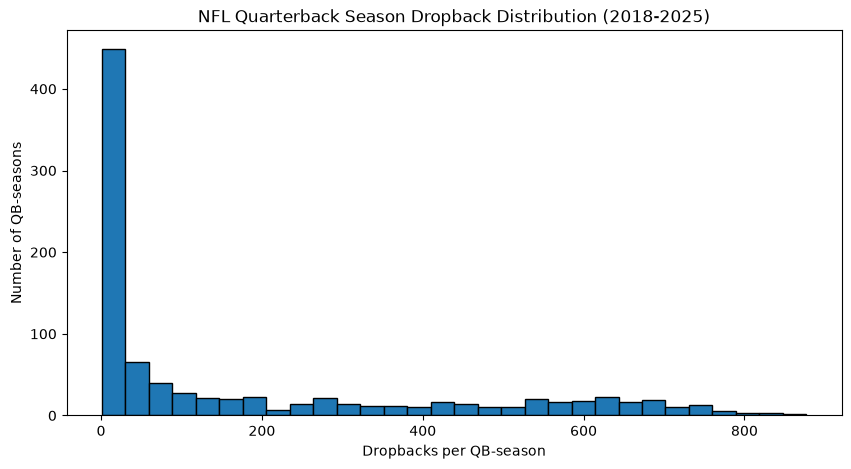

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    qb_season_stats["dropbacks"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Dropbacks per QB-season")
plt.ylabel("Number of QB-seasons")
plt.title("NFL Quarterback Season Dropback Distribution (2018-2025)")

plt.show()

### 13.12 - Interpret the Dropback Distribution

The results revealed:
- Total player seasons: 938
- Median dropbacks: 39.5
- Mean dropbacks: 180.9

The mean is substantially larger than the median. This means the distribution is strongly right skewed: a relatively small group of players accounts for many dropbacks, while a large number have very limited opportunities.

The threshold analysis reinforces that:
| Minimum dropbacks | Remaining player seasons | Retained |
| :--- | :--- | :--- |
| 50 | 441 | 47.0% |
| 100 | 370 | 39.4% |
| 200 | 297 | 31.7% |
| 300 | 244 | 26.0% |
| 400 | 204 | 21.7% |
| 500 | 159 | 17.0% |

These counts still include occasional non-QB passers, so they're preliminary. At a 300 dropback threshold, 74% of the player season observations would be excluded. That isn't automatically wrong to do, but it could substantially change what the study is.

### 13.13 - Next Step: Identify Low Volume Observations

Before calculating year over year quarterback performance, investigating exactly who's contributing those extremely small observations is essential. The two situations to look out for are actual quarterbacks with limited playing time and non-quarterbacks who recorded a pass attempt on a trick play.

In [61]:
low_volume_seasons = (
    qb_season_stats[
        qb_season_stats["dropbacks"] < 50
    ]
    .sort_values("dropbacks")
)

print("Low-volume player seasons:", len(low_volume_seasons))

print("\nUnqiue players:", low_volume_seasons["qb_id"].nunique())

low_volume_seasons[
    ["season", "qb_name", "dropbacks", "epa_per_dropback"]
].head(25)

Low-volume player seasons: 497

Unqiue players: 281


,season,qb_name,dropbacks,epa_per_dropback
47,2018,T.Way,1,2.734389
48,2018,K.Allen,1,-1.585331
51,2018,D.Hopkins,1,-0.445596
53,2018,A.Wilson,1,4.351976
54,2018,C.Boswell,1,3.991391
57,2018,L.Thomas,1,3.806632
908,2025,X.Hutchinson,1,0.914211
909,2025,M.Mapu,1,-2.482691
915,2025,I.Williams,1,-0.818771
917,2025,A.McNamara,1,2.856504


### 13.14 - Cleaning the Quarterback Sample Without Eliminating Developmental History
The latest results show something that needs to be addressed:
- 497 of the 938 player season observations have fewer than 50 dropbacks.
- These represent 281 unique players
- Several of the one dropback observations are clearly not quarterbacks. For example, DeAndre Hopkins, Russell Gage era trick play participants, and other receivers or specialists may attempt occasional passes.

That means the current `qb_season_stats` dataset is more accuractly described as a dropback player dataset rather than a pure quarterback dataset. Theres situations to account for:
| Situation | Our treatment |
| :--- | :--- |
| Actual QB with limited NFL experience | Retain his season, including his dropbacks and EPA |
| Non-QB who throws a trick-play pass | Exclude from the QB development analysis |
| QB who missed games due to injury | Retain season and eventually add injury/availability context |
| QB with 600 dropbacks | Retain season; performance estimate has substantially more evidence |

Importantly, there is non 50 dropback minimum threshold being introduced here. Low volume seasons shouldn't be discarded. If they were, there could be situations where the interpretation of a strong quarterback performance in 2023 as that quarterback's rookie season may not be the case when they played some snaps in 2022 and sat on the bench learned the playbook. Including that 2022 seasons could however describe something more nuanced; he had limited early playing experience, followed by increased opportunity and improved observed performance. It does not however, establish that those 40 dropbacks caused the improvement. Development, coaching, personnel, opponents, and other factors could explain the change.

The first step is to examine how many of the one dropback player seasons belong to actual quarterbacks versus other positions. That way observations that require further classification can be identified and sorted. The next step is to merge player roster/position information using player IDs rather than guess based on names. After that another longitudinal QB dataset will be built to preserve every season, including limited playing time and eventually calculate:
$$\text{Career Dropbacks Through Year } t = \sum_{k=1}^{t} N_{ik}$$
This cumulative measure will help distinguish a true rookie from a quarterback who has already spent time gaining NFL game experience. Another thig to track is years since NFL entry separately from actual game experience, because a quarterback can develop through practice and coaching without recording many dropbacks.


In [62]:
one_dropback_seasons = (
    qb_season_stats[
        qb_season_stats["dropbacks"] == 1
    ]
    .sort_values(["season", "qb_name"])
)

print(
    "One-dropback player-seasons:",
    len(one_dropback_seasons)
)

one_dropback_seasons[
    ["season", "qb_name", "dropbacks", "epa_per_dropback"]
].head(30)

One-dropback player-seasons: 259


,season,qb_name,dropbacks,epa_per_dropback
27,2018,A.Brown,1,-0.457092
100,2018,A.Miller,1,1.581323
53,2018,A.Wilson,1,4.351976
43,2018,B.Anger,1,-2.903443
60,2018,B.Ellington,1,-0.440122
35,2018,C.Beasley,1,-0.481403
104,2018,C.Bojorquez,1,-2.963833
54,2018,C.Boswell,1,3.991391
83,2018,C.McCaffrey,1,6.549202
96,2018,C.Wadman,1,3.393739


In [63]:
rosters = nfl.load_rosters(seasons).to_pandas()

print("Roster shape:", rosters.shape)

print("\nAvailable columns:")
print(rosters.columns.tolist())

rosters.head()

Roster shape: (24862, 36)

Available columns:
['season', 'team', 'position', 'depth_chart_position', 'jersey_number', 'status', 'full_name', 'first_name', 'last_name', 'birth_date', 'height', 'weight', 'college', 'gsis_id', 'espn_id', 'sportradar_id', 'yahoo_id', 'rotowire_id', 'pff_id', 'pfr_id', 'fantasy_data_id', 'sleeper_id', 'years_exp', 'headshot_url', 'ngs_position', 'week', 'game_type', 'status_description_abbr', 'football_name', 'esb_id', 'gsis_it_id', 'smart_id', 'entry_year', 'rookie_year', 'draft_club', 'draft_number']


,season,team,position,depth_chart_position,jersey_number,status,full_name,first_name,last_name,birth_date,height,weight,college,gsis_id,espn_id,sportradar_id,yahoo_id,rotowire_id,pff_id,pfr_id,fantasy_data_id,sleeper_id,years_exp,headshot_url,ngs_position,week,game_type,status_description_abbr,football_name,esb_id,gsis_it_id,smart_id,entry_year,rookie_year,draft_club,draft_number
0,2018,ARI,K,K,4.0,RES,Phil Dawson,Phil,Dawson,1975-01-23,71.0,200.0,Texas,00-0004091,1440,e5247e5f-c4af-4a9b-8c7c-da75ef7fbf8d,4269,994,422,NaN,5714,229,20.0,https://static.www.nfl.com/image/private/f_aut...,NaN,17,REG,NaN,Phil,DAW705989,23860,32004441-5770-5989-ac23-bf6cdafcb988,1998.0,1998.0,NaN,NaN
1,2018,IND,K,K,4.0,ACT,Adam Vinatieri,Adam,Vinatieri,1972-12-28,72.0,212.0,South Dakota State,00-0016919,1097,9ecf8040-10f9-4a5c-92da-1b4d77bd6760,3727,395,226,NaN,3258,120,22.0,https://static.www.nfl.com/image/private/f_aut...,NaN,19,DIV,A01,Adam,VIN196019,21213,32005649-4e19-6019-e626-0b58f9aa81e1,1996.0,1996.0,NaN,NaN
2,2018,NE,QB,QB,12.0,ACT,Tom Brady,Tom,Brady,1977-08-03,76.0,225.0,Michigan,00-0019596,2330,41c44740-d0f6-44ab-8347-3b5d515e5ecf,5228,1350,698,BradTo00,4314,167,18.0,https://static.www.nfl.com/image/private/f_aut...,QB,21,SB,A01,Tom,BRA371156,25511,32004252-4137-1156-7ed0-8b9e44948f13,2000.0,2000.0,NE,199.0
3,2018,SEA,K,K,11.0,ACT,Sebastian Janikowski,Sebastian,Janikowski,1978-03-02,73.0,258.0,Florida State,00-0019646,2148,480277d1-47c9-44df-969e-038a84cd0fea,5046,1299,595,janikseb01,3253,118,18.0,https://static.www.nfl.com/image/private/f_aut...,NaN,18,WC,A01,Sebastian,JAN400354,25326,32004a41-4e40-0354-af49-976718aaf8be,2000.0,2000.0,OAK,17.0
4,2018,HOU,P,P,9.0,CUT,Shane Lechler,Shane,Lechler,NaT,74.0,230.0,Texas A&M,00-0019714,2273,c4b15bec-4adf-444a-bda1-5a07ade70abf,5171,7123,673,LechSh20,7606,307,18.0,https://static.www.nfl.com/image/private/f_aut...,NaN,18,WC,NaN,Shane,LEC090322,25451,32004c45-4309-0322-4493-968eaa2c1214,2000.0,2000.0,OAK,NaN


### 13.16 - Prepare Roster Data for the QB Dataset

The roster dataset contains 24,862 records and 36 columns across the 2018–2025 seasons. The first step is to check duplicates first, a player might appear in multiple roster records within the same season, particularly if he changes teams. By merging those records directly, one quarterback-season observation could match multiple roster rows. For example, a QB with 400 dropbacks could accidentally appear twice after the merge. That would introduce duplicate observations into the analysis. A roster lookup containing one record per player per season while checking for conflicting positions could prevent this issue.

In [64]:
roster_duplicates = (
    rosters
    .groupby(["season", "gsis_id"])
    .size()
    .reset_index(name="records")
)

print(
    "Player-season combinations with multiple roster records:",
    (roster_duplicates["records"] > 1).sum()
)

roster_duplicates[
    roster_duplicates["records"] > 1
].head(15)

Player-season combinations with multiple roster records: 1


,season,gsis_id,records
6221,2019,00-0035718,2


### 13.17 - Investigate Duplicate Roster Records
Among the player seasons combinations with nonmissing `gsis_id` values, only one has multiple roster records. So investigating this duplicated player is warrented.

In [65]:
duplicate_player = rosters[
    (rosters["season"] == 2019) &
    (rosters["gsis_id"] == "00-0035718")
]

duplicate_player[
    [
        "season",
        "gsis_id",
        "full_name",
        "team",
        "position",
        "depth_chart_position",
        "status"
    ]
]

,season,gsis_id,full_name,team,position,depth_chart_position,status
6222,2019,00-0035718,Isaiah Searight,NYG,DL,NT,RES
6223,2019,00-0035718,Quinnen Williams,NYJ,DL,NT,ACT


In [66]:
print("Total roster records:", len(rosters))

print(
    "Missing GSIS IDs:",
    rosters["gsis_id"].isna().sum()
)

print(
    "Missing positions:",
    rosters["position"].isna().sum()
)

print(
    "\nRoster position distribution:"
)

print(
    rosters["position"]
    .value_counts(dropna=False)
    .head(20)
)

Total roster records: 24862
Missing GSIS IDs: 10
Missing positions: 0

Roster position distribution:
position
DB    4714
OL    4260
DL    3666
WR    3234
LB    3229
RB    1913
TE    1685
QB    1014
K      428
P      368
LS     351
Name: count, dtype: int64


### 13.18 - Create a Reliable Quarterback Roster Lookup
Filter the seasonal roster dataset to players classified as quarterbacks. Retain player identifiers and seasons so the records can be matched to the quarterback-season performance dataset. Check for missing or duplicated keys before merging.

In [67]:
qb_roster_lookup = (
    rosters.loc[
        (rosters["position"] == "QB")
        & rosters["gsis_id"].notna(),
        ["season", "gsis_id", "full_name", "team"]
    ]
    .copy()
)

print("QB roster records:", len(qb_roster_lookup))

print(
    "Unique QB players:",
    qb_roster_lookup["gsis_id"].nunique()
)

print(
    "Duplicate QB-season identifiers:",
    qb_roster_lookup.duplicated(
        subset=["season", "gsis_id"]
    ).sum()
)

qb_roster_lookup.head(10)

QB roster records: 1013
Unique QB players: 282
Duplicate QB-season identifiers: 0


,season,gsis_id,full_name,team
2,2018,00-0019596,Tom Brady,NE
5,2018,00-0020531,Drew Brees,NO
8,2018,00-0021206,Josh McCown,NYJ
16,2018,00-0022787,Matt Schaub,ATL
17,2018,00-0022803,Eli Manning,NYG
20,2018,00-0022924,Ben Roethlisberger,PIT
21,2018,00-0022942,Philip Rivers,LAC
29,2018,00-0023436,Alex Smith,WAS
33,2018,00-0023459,Aaron Rodgers,GB
38,2018,00-0023645,Derek Anderson,BUF


### 13.19 - Merge Quarterback Rosters with Season Performance
Merge quarterback-season performance observations with the seasonal quarterback roster lookup. The merge will preserve every original performance observation and identify which players match an official QB roster record.

In [68]:
qb_season_merged = qb_season_stats.merge(
    qb_roster_lookup,
    left_on=["season", "qb_id"],
    right_on=["season", "gsis_id"],
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Original QB-season observations:", len(qb_season_stats))
print("Merged observations:", len(qb_season_merged))

print("\nMerge results:")
print(qb_season_merged["_merge"].value_counts())

qb_season_merged.head(10)

Original QB-season observations: 938
Merged observations: 938

Merge results:


_merge
both          625
left_only     313
right_only      0
Name: count, dtype: int64


,season,qb_id,qb_name,dropbacks,total_epa,epa_per_dropback,scrambles,sacks,scramble_rate,sack_rate,gsis_id,full_name,team,_merge
0,2018,00-0019596,T.Brady,721,112.801873,0.156452,5.0,22.0,0.006935,0.030513,00-0019596,Tom Brady,NE,both
1,2018,00-0020531,D.Brees,593,155.444491,0.262132,4.0,21.0,0.006745,0.035413,00-0020531,Drew Brees,NO,both
2,2018,00-0021206,J.McCown,121,-29.596209,-0.244597,5.0,7.0,0.041322,0.057851,00-0021206,Josh McCown,NYJ,both
3,2018,00-0022787,M.Schaub,7,-2.436508,-0.348073,0.0,0.0,0.000000,0.000000,00-0022787,Matt Schaub,ATL,both
4,2018,00-0022803,E.Manning,631,22.877588,0.036256,4.0,47.0,0.006339,0.074485,00-0022803,Eli Manning,NYG,both
5,2018,00-0022921,L.Fitzgerald,1,3.088043,3.088043,0.0,0.0,0.000000,0.000000,NaN,NaN,NaN,left_only
6,2018,00-0022924,B.Roethlisberger,713,135.582294,0.190157,12.0,24.0,0.016830,0.033661,00-0022924,Ben Roethlisberger,PIT,both
7,2018,00-0022942,P.Rivers,643,129.665531,0.201657,7.0,35.0,0.010886,0.054432,00-0022942,Philip Rivers,LAC,both
8,2018,00-0023436,A.Smith,370,-8.620847,-0.023300,21.0,22.0,0.056757,0.059459,00-0023436,Alex Smith,WAS,both
9,2018,00-0023459,A.Rodgers,680,76.739856,0.112853,33.0,49.0,0.048529,0.072059,00-0023459,Aaron Rodgers,GB,both


### 13.20 - Investigate Unmatched Player-Seasons
Examine the distribution of dropbacks among unmatched observations to distinguish likely trick-play participants from potential quarterbacks missing from the roster lookup.

In [69]:
unmatched = qb_season_merged[
    qb_season_merged["_merge"] == "left_only"
].copy()

print("Unmatched player-seasons:", len(unmatched))

print("\nDropback distribution:")
print(
    unmatched["dropbacks"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nUnmatched observations by dropback volume:")

for threshold in [1, 2, 5, 10, 25, 50, 100]:
    count = (unmatched["dropbacks"] >= threshold).sum()
    print(f"At least {threshold} dropbacks: {count}")

print("\nHighest-volume unmatched players:")

display(
    unmatched[
        ["season", "qb_name", "dropbacks", "epa_per_dropback"]
    ]
    .sort_values("dropbacks", ascending=False)
    .head(20)
)

Unmatched player-seasons: 313

Dropback distribution:
count    313.000000
mean       1.412141
std        1.425314
min        1.000000
50%        1.000000
75%        1.000000
90%        2.000000
95%        3.000000
99%        4.880000
max       21.000000
Name: dropbacks, dtype: float64

Unmatched observations by dropback volume:
At least 1 dropbacks: 313
At least 2 dropbacks: 70
At least 5 dropbacks: 4
At least 10 dropbacks: 2
At least 25 dropbacks: 0
At least 50 dropbacks: 0
At least 100 dropbacks: 0

Highest-volume unmatched players:


,season,qb_name,dropbacks,epa_per_dropback
525,2022,T.Hill,21,0.599342
336,2020,K.Hinton,11,-1.174131
33,2018,J.Hekker,5,0.680047
195,2019,J.Samuels,5,-0.702292
749,2024,T.Hill,4,-0.804423
467,2021,J.Jefferson,4,0.313334
345,2020,L.Bowden,4,0.514651
273,2020,J.Landry,4,1.790106
655,2023,J.Meyers,4,0.586254
569,2022,J.Jefferson,4,0.286890


### 13.21 - Construct the Roster-Confirmed QB Dataset
Retain player-seasons that match an official quarterback roster record. Unmatched observations remain available separately for investigation, rather than being deleted from the source data.

In [70]:
qb_confirmed = (
    qb_season_merged.loc[
        qb_season_merged["_merge"] == "both"
    ]
    .drop(columns=["_merge"])
    .copy()
)

qb_unmatched_review = unmatched.copy()

print("Confirmed QB-seasons:", len(qb_confirmed))

print(
    "Unique quarterbacks:",
    qb_confirmed["qb_id"].nunique()
)

print(
    "Seaons covered:",
    sorted(qb_confirmed["season"].unique())
)

print("\nQB-seasons per year:")

print(
    qb_confirmed["season"]
    .value_counts()
    .sort_index()
)

Confirmed QB-seasons: 625
Unique quarterbacks: 167
Seaons covered: [np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]

QB-seasons per year:
season
2018    70
2019    73
2020    81
2021    81
2022    83
2023    80
2024    78
2025    79
Name: count, dtype: int64


### 13.22 - Examine Longitudinal QB Coverage
Calculate how many seasons each quarterback appears in the dataset, identify their first and last observed seasons, and measure their total dropback experience during the observation window.

In [71]:
qb_career_coverage = (
    qb_confirmed
    .groupby(["qb_id", "full_name"], as_index=False)
    .agg(
        seasons_observed=("season", "nunique"),
        first_observed_season=("season", "min"),
        last_observed_season=("season", "max"),
        total_dropbacks=("dropbacks", "sum")
    )
)

print("Career coverage distribution:")

print(
    qb_career_coverage["seasons_observed"]
    .value_counts()
    .sort_index()
)

print("\nQuarterbacks with the most observed seasons:")

display(
    qb_career_coverage
    .sort_values(
        ["seasons_observed", "total_dropbacks"],
        ascending=False
    )
    .head(15)
)

Career coverage distribution:
seasons_observed
1    47
2    26
3    18
4    17
5    16
6    17
7     9
8    19
Name: count, dtype: int64

Quarterbacks with the most observed seasons:


,qb_id,full_name,seasons_observed,first_observed_season,last_observed_season,total_dropbacks
71,00-0033873,Patrick Mahomes,8,2018,2025,6055
86,00-0034857,Josh Allen,8,2018,2025,5293
61,00-0033106,Jared Goff,8,2018,2025,5205
85,00-0034855,Baker Mayfield,8,2018,2025,4635
17,00-0026498,Matthew Stafford,8,2018,2025,4618
59,00-0033077,Dak Prescott,8,2018,2025,4465
8,00-0023459,Aaron Rodgers,8,2018,2025,4461
30,00-0029604,Kirk Cousins,8,2018,2025,4229
28,00-0029263,Russell Wilson,8,2018,2025,4025
84,00-0034796,Lamar Jackson,8,2018,2025,3733


### 13.23 - Identify Consecutive QB Seasons
Sort each quarterback's observations chronologically, calculate the difference between consecutive observed seasons, and determine how many valid year-over-year comparisons the dataset supports.

In [72]:
qb_longitudinal = (
    qb_confirmed
    .sort_values(["qb_id", "season"])
    .copy()
)

# Previous observed season for each quarterback
qb_longitudinal["previous_season"] = (
    qb_longitudinal
    .groupby("qb_id")["season"]
    .shift(1)
)

# Number of calendar years between observations
qb_longitudinal["season_gap"] = (
    qb_longitudinal["season"]
    - qb_longitudinal["previous_season"]
)

# Is this observation immediately after the previous one?
qb_longitudinal["consecutive_season"] = (
    qb_longitudinal["season_gap"] == 1
)

print("Season gap distribution:")

print(
    qb_longitudinal["season_gap"]
    .value_counts(dropna=False)
    .sort_index()
)

print(
    "\nConsecutive year-over-year comparisons:",
    qb_longitudinal["consecutive_season"].sum()
)

Season gap distribution:
season_gap
0.0      7
1.0    413
2.0     33
3.0      4
5.0      1
NaN    167
Name: count, dtype: int64

Consecutive year-over-year comparisons: 413


### 13.24 - Investigate Duplicate Quarterback Season Records
The next step is to investigate the 7 observations where `season_gap == 0` before calculating year-over-year changes in quarterback performance.

In [73]:
duplicate_qb_seasons = qb_longitudinal[
    qb_longitudinal["season_gap"] == 0
]

print(
    "Duplicate QB-season observations:",
    len(duplicate_qb_seasons)
)

display(
    duplicate_qb_seasons[
        [
            "season",
            "qb_id",
            "qb_name",
            "full_name",
            "team",
            "dropbacks",
            "total_epa",
            "epa_per_dropback"
        ]
    ]
)

Duplicate QB-season observations: 7


,season,qb_id,qb_name,full_name,team,dropbacks,total_epa,epa_per_dropback
354,2021,00-0023459,Aa.Rodgers,Aaron Rodgers,GB,281,47.639411,0.169535
369,2021,00-0028118,Ty.Taylor,Tyrod Taylor,HOU,49,29.639803,0.604894
145,2019,00-0029665,R.Griffin III,Robert Griffin III,BAL,38,-8.135603,-0.214095
206,2019,00-0034857,Jos.Allen,Josh Allen,BUF,102,22.050533,0.216182
439,2021,00-0034857,Jos.Allen,Josh Allen,BUF,46,18.293450,0.397684
218,2019,00-0035289,G.Minshew II,Gardner Minshew,JAX,332,-3.480580,-0.010484
328,2020,00-0035289,G.Minshew II,Gardner Minshew,JAX,254,15.354256,0.060450


In [74]:
duplicate_ids = duplicate_qb_seasons["qb_id"].unique()

display(
    qb_longitudinal[
        qb_longitudinal["qb_id"].isin(duplicate_ids)
    ][
        [
            "season",
            "qb_id",
            "full_name",
            "team",
            "dropbacks",
            "total_epa",
            "epa_per_dropback"
        ]
    ].sort_values(["qb_id", "season"])
)

,season,qb_id,full_name,team,dropbacks,total_epa,epa_per_dropback
9,2018,00-0023459,Aaron Rodgers,GB,680,76.739856,0.112853
117,2019,00-0023459,Aaron Rodgers,GB,705,86.181740,0.122244
232,2020,00-0023459,Aaron Rodgers,GB,659,213.724764,0.324317
353,2021,00-0023459,Aaron Rodgers,GB,328,86.278612,0.263045
354,2021,00-0023459,Aaron Rodgers,GB,281,47.639411,0.169535
483,2022,00-0023459,Aaron Rodgers,GB,588,-3.676633,-0.006253
597,2023,00-0023459,Aaron Rodgers,NYJ,2,-2.031960,-1.015980
718,2024,00-0023459,Aaron Rodgers,NYJ,643,4.444520,0.006912
833,2025,00-0023459,Aaron Rodgers,PIT,575,-7.958206,-0.013840
32,2018,00-0028118,Tyrod Taylor,CLE,107,-19.189912,-0.179345


Look at Aaron Rodgers in 2021:
| Season | Dropbacks | Total EPA | EPA/dropback |
| :--- | :--- | :--- | :--- |
| 2021 - Record 1 | 328 | 86.28 | 0.263 |
| 2021 - Record 2 | 281 | 47.64 | 0.170 |

Both records have the same quarterback ID, team, and season. Together the represent:
$$N = 328 + 281 = 609$$
$$EPA_{\text{total}} = 86.28 + 47.64 = 133.92$$
$$EPA/DB = \frac{133.92}{609} \approx 0.220$$
This is an example of why deleting one record or averaging the two EPA/dropback values is wrong. It's unclear whether these records represent different sets of plays or whether the underlying data contains an identificaiton issue. That warrents investigation before combining them.

This could be happening because the original aggregation grouped by `["season", "qb_id", "qb_name"]`. If the same quarterback has different name representations within a season, pandas treats them as different groups even when `qb_id` is identical. 

In [75]:
duplicate_keys = (
    qb_confirmed[
        qb_confirmed.duplicated(
            subset=["season", "qb_id"],
            keep=False
        )
    ]
    .sort_values(["qb_id", "season", "qb_name"])
)

display(
    duplicate_keys[
        [
            "season",
            "qb_id",
            "qb_name",
            "full_name",
            "team",
            "dropbacks",
            "total_epa",
            "epa_per_dropback"
        ]
    ]
)

,season,qb_id,qb_name,full_name,team,dropbacks,total_epa,epa_per_dropback
353,2021,00-0023459,A.Rodgers,Aaron Rodgers,GB,328,86.278612,0.263045
354,2021,00-0023459,Aa.Rodgers,Aaron Rodgers,GB,281,47.639411,0.169535
368,2021,00-0028118,T.Taylor,Tyrod Taylor,HOU,128,-37.447892,-0.292562
369,2021,00-0028118,Ty.Taylor,Tyrod Taylor,HOU,49,29.639803,0.604894
144,2019,00-0029665,R.Griffin,Robert Griffin III,BAL,6,8.937259,1.489543
145,2019,00-0029665,R.Griffin III,Robert Griffin III,BAL,38,-8.135603,-0.214095
205,2019,00-0034857,J.Allen,Josh Allen,BUF,489,-17.053734,-0.034875
206,2019,00-0034857,Jos.Allen,Josh Allen,BUF,102,22.050533,0.216182
438,2021,00-0034857,J.Allen,Josh Allen,BUF,744,149.399857,0.200806
439,2021,00-0034857,Jos.Allen,Josh Allen,BUF,46,18.293450,0.397684


### 13.25 - Rebuilding QB Season Statistics Using Stable Player Identifiers
The problem was inconsistent quarterback names, not duplicate plays. Fix the underlying aggregation rather than deleting records from `qb_confirmed`.

In [76]:
qb_season_stats_fixed = (
    qb_plays_clean
    .groupby(["season", "qb_id"], as_index=False)
    .agg(
        dropbacks=("epa", "size"),
        total_epa=("epa", "sum"),
        epa_per_dropback=("epa", "mean"),
        scrambles=("qb_scramble", "sum"),
        sacks=("sack", "sum")
    )
)

qb_season_stats_fixed["scramble_rate"] = (
    qb_season_stats_fixed["scrambles"]
    / qb_season_stats_fixed["dropbacks"]
)

qb_season_stats_fixed["sack_rate"] = (
    qb_season_stats_fixed["sacks"]
    / qb_season_stats_fixed["dropbacks"]
)

print("Original QB-season rows:", len(qb_season_stats))
print("Corrected QB-season rows:", len(qb_season_stats_fixed))

print(
    "Duplicate QB-season indentifiers:",
    qb_season_stats_fixed.duplicated(
        ["season", "qb_id"]
    ).sum()
)

Original QB-season rows: 938
Corrected QB-season rows: 930
Duplicate QB-season indentifiers: 0


In [77]:
print(
    "Original dropbacks:",
    qb_season_stats["dropbacks"].sum()
)

print(
    "Corrected dropbacks:",
    qb_season_stats_fixed["dropbacks"].sum()
)

print(
    "Original total EPA:",
    qb_season_stats["total_epa"].sum()
)

print(
    "Corrected total EPA:",
    qb_season_stats_fixed["total_epa"].sum()
)

Original dropbacks: 169638
Corrected dropbacks: 169638
Original total EPA: 7091.801285525184
Corrected total EPA: 7091.801285525184


### 13.26 - Reconnect the Correct Data to Confirmed NFL Quarterbacks
Now that each player has exactly one observation per season, the roster merge needs to be rebuilt. This matters because preserving the two research dimensions:
- Opportunity: How many NFL dropbacks did a quarterback receive?
- Performance: How efficiently did he peform during those opportunities?
is important. Additionally retaining low volume seasons is imperative so that development trajectories can be studied without mistakenly treating later success as immediate NFL readiness.

In [79]:
qb_confirmed_fixed = qb_season_stats_fixed.merge(
    qb_roster_lookup,
    left_on=["season", "qb_id"],
    right_on=["season", "gsis_id"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Corrected QB-season observations:", len(qb_confirmed_fixed))

print("\nRoster matching results:")
print(qb_confirmed_fixed["_merge"].value_counts())

print("\nUnmatched observations with at least 25 dropbacks:")
print(
    qb_confirmed_fixed[
        (qb_confirmed_fixed["_merge"] == "left_only")
        & (qb_confirmed_fixed["dropbacks"] >= 25)
    ][["season", "qb_id", "dropbacks"]]
)

Corrected QB-season observations: 930

Roster matching results:
_merge
both          618
left_only     312
right_only      0
Name: count, dtype: int64

Unmatched observations with at least 25 dropbacks:
Empty DataFrame
Columns: [season, qb_id, dropbacks]
Index: []


### 13.27 - Rebuild the QB Development Timeline

Objective

For every quarterback, it's essential to know:
1. When did was the first observation of them playing?
2. How many seasons have there been observations of them playing?
3. How may dropbacks have them accumulated?
4. How much NFL playing experience did they have before each season?

The fourth question is especially important for the research hypothesis. A quarterback who performs well in his third NFL season isn't necessarily someone who was NFL ready immediately.

### 13.28 - Measure Gaps Between Observed Seasons
Examine whether a quarterback played in consecutive seasons or had a gap in his recorded NFL appearances. Calender time and playing experience are not the same thing. A quarterback might spend a year developing on the bench without recording any dropbacks, or miss a season due to injury.

In [81]:
qb_development = (
    qb_confirmed_fixed.loc[
        qb_confirmed_fixed["_merge"] == "both"
    ]
    .drop(columns=["_merge", "gsis_id"])
    .sort_values(["qb_id", "season"])
    .reset_index(drop=True)
    .copy()
)

# Number of previously observed seasons with dropbacks
qb_development["prior_seasons_observed"] = (
    qb_development.groupby("qb_id").cumcount()
)

# Total NFL dropbacks accumulated before the current season
qb_development["prior_career_dropbacks"] = (
    qb_development.groupby("qb_id")["dropbacks"].cumsum()
    - qb_development["dropbacks"]
)

# First season observed within our dataset
qb_development["first_observed_season"] = (
    qb_development.groupby("qb_id")["season"].transform("min")
)

# Years elapsed since first observed season
qb_development["years_since_first_observed"] = (
    qb_development["season"]
    - qb_development["first_observed_season"]
)

print("QB development observations:", len(qb_development))

print(
    "Duplicate QB-season identifiers:",
    qb_development.duplicated(["season", "qb_id"]).sum()
)

display(
    qb_development[
        [
            "season",
            "full_name",
            "dropbacks",
            "prior_seasons_observed",
            "prior_career_dropbacks",
            "years_since_first_observed"
        ]
    ].head(15)
)

QB development observations: 618
Duplicate QB-season identifiers: 0


,season,full_name,dropbacks,prior_seasons_observed,prior_career_dropbacks,years_since_first_observed
0,2018,Tom Brady,721,0,0,0
1,2019,Tom Brady,682,1,721,1
2,2020,Tom Brady,777,2,1403,2
3,2021,Tom Brady,848,3,2180,3
4,2022,Tom Brady,832,4,3028,4
5,2018,Drew Brees,593,0,0,0
6,2019,Drew Brees,423,1,593,1
7,2020,Drew Brees,477,2,1016,2
8,2018,Josh McCown,121,0,0,0
9,2019,Josh McCown,37,1,121,1


In [82]:
# Identify the previous observed observed season for each QB
qb_development["previous_observed_season"] = (
    qb_development
    .groupby("qb_id")["season"]
    .shift(1)
)

# Calculate the number of season between observations
qb_development["season_gap"] = (
    qb_development["season"]
    - qb_development["previous_observed_season"]
)

# Count full seasons without an observed dropback
qb_development["seasons_without_observed_play"] = (
    qb_development["season_gap"] - 1
).clip(lower=0)

print("Season gap distribution:")
print(
    qb_development["season_gap"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nQuarterbacks returning after at least one unobserved season:")

display(
    qb_development.loc[
        qb_development["seasons_without_observed_play"] >= 1,
        [
            "full_name",
            "season",
            "previous_observed_season",
            "season_gap",
            "seasons_without_observed_play",
            "prior_career_dropbacks",
            "dropbacks",
        ]
    ].sort_values(
        ["season_gap", "full_name"],
        ascending=[False, True]
    ).head(20)
)

Season gap distribution:
season_gap
1.0    413
2.0     33
3.0      4
5.0      1
NaN    167
Name: count, dtype: int64

Quarterbacks returning after at least one unobserved season:


,full_name,season,previous_observed_season,season_gap,seasons_without_observed_play,prior_career_dropbacks,dropbacks
21,Philip Rivers,2025,2020.0,5.0,4.0,1881,97
184,AJ McCarron,2023,2020.0,3.0,2.0,53,6
432,Easton Stick,2023,2020.0,3.0,2.0,1,196
57,Josh Johnson,2021,2018.0,3.0,2.0,115,92
353,Logan Woodside,2023,2020.0,3.0,2.0,3,6
23,Alex Smith,2020,2018.0,2.0,1.0,370,277
91,Blaine Gabbert,2020,2018.0,2.0,1.0,106,19
232,Brandon Allen,2024,2022.0,2.0,1.0,294,33
406,Brett Rypien,2025,2023.0,2.0,1.0,183,1
322,C.J. Beathard,2020,2018.0,2.0,1.0,200,114


### 13.29 - Build Career Level Opportunity and Performance Summaries
Create one observation per quarterback, summarizing their performance across the entire 2018-2025 dataset.

The two central dimensions remain:

**Opportunity**
$$O_i = \sum_{t} D_{i,t}$$
Total observed dropbacks across season.

**Performance**
$$P_i = \frac{\sum_{t} \text{EPA}_{i,t}}{\sum_{t} D_{i,t}}$$
Career EPA per dropback, weighted by actual playing volume.

Using the second formula rather than averaging seasonal EPA rates equally. Otherwise, a season with five dropbacks would influence a quarterback's career average as much as a season with 700 dropbacks.

In [92]:
qb_career_summary = (
    qb_development
    .groupby("qb_id", as_index=False)
    .agg(
        full_name=("full_name", "first"),
        first_observed_season=("season", "min"),
        last_observed_season=("season", "max"),
        seasons_observed=("season", "nunique"),
        total_dropbacks=("dropbacks", "sum"),
        total_epa=("total_epa", "sum"),
        total_scramble=("scrambles", "sum"),
        total_sacks=("sacks", "sum")
    )
)

# Career performance measures
qb_career_summary["career_epa_per_dropback"] = (
    qb_career_summary["total_epa"]
    / qb_career_summary["total_dropbacks"]
)

qb_career_summary["career_scramble_rate"] = (
    qb_career_summary["total_scramble"]
    / qb_career_summary["total_dropbacks"]
)

qb_career_summary["career_sack_rate"] = (
    qb_career_summary["total_sacks"]
    / qb_career_summary["total_dropbacks"]
)

print("Unique quarterbacks:", len(qb_career_summary))

print(
    "Total dropbacks preserved:",
    qb_career_summary["total_dropbacks"].sum()
    == qb_development["dropbacks"].sum()
)

print(
    "Total EPA preserved:",
    abs(
        qb_career_summary["total_epa"].sum()
        - qb_development["total_epa"].sum()
    ) < 1e-8
)

display(
    qb_career_summary[
        [
            "full_name",
            "seasons_observed",
            "total_dropbacks",
            "career_epa_per_dropback",
            "career_scramble_rate",
            "career_sack_rate"
        ]
    ]
    .sort_values("total_dropbacks", ascending=False)
    .head(15)
)

Unique quarterbacks: 167
Total dropbacks preserved: True
Total EPA preserved: True


,full_name,seasons_observed,total_dropbacks,career_epa_per_dropback,career_scramble_rate,career_sack_rate
69,Patrick Mahomes,8,6055,0.231850,0.064575,0.043270
84,Josh Allen,8,5293,0.169294,0.075005,0.049310
60,Jared Goff,8,5205,0.118902,0.021326,0.048991
83,Baker Mayfield,8,4635,0.064685,0.048112,0.063862
17,Matthew Stafford,8,4618,0.120797,0.018190,0.055868
58,Dak Prescott,8,4465,0.130530,0.037178,0.054423
8,Aaron Rodgers,8,4461,0.112383,0.032056,0.057386
30,Kirk Cousins,8,4229,0.067271,0.018444,0.058406
28,Russell Wilson,8,4025,0.052634,0.065590,0.083975
109,Justin Herbert,6,3989,0.088376,0.050639,0.059664


### 13.30 - Validate the Career Metrics
Quality control check.

In [94]:
import numpy as np

career_metrics = [
    "career_epa_per_dropback",
    "career_scramble_rate",
    "career_sack_rate"
]

print("Missing values:")
print(qb_career_summary[career_metrics].isna().sum())

print("\nInfinite values:")
print(
    np.isinf(
        qb_career_summary[career_metrics].to_numpy()
    ).sum()
)

print("\nQuarterbacks with zero dropbacks:")
print(
    (qb_career_summary["total_dropbacks"] == 0).sum()
)

print("\nCareer metric distributions:")
display(
    qb_career_summary[career_metrics].describe()
)

Missing values:
career_epa_per_dropback    0
career_scramble_rate       0
career_sack_rate           0
dtype: int64

Infinite values:
0

Quarterbacks with zero dropbacks:
0

Career metric distributions:


,career_epa_per_dropback,career_scramble_rate,career_sack_rate
count,167.000000,167.000000,167.000000
mean,-0.160165,0.046680,0.083604
std,0.440802,0.033674,0.109397
min,-3.840493,0.000000,0.000000
25%,-0.250500,0.021312,0.052566
50%,-0.077271,0.043307,0.068006
75%,0.052286,0.066822,0.086735
max,2.143627,0.152174,1.000000


### 13.31 - Investigate Extreme Career Performance Values
Identify the quarterbacks responsible for the extreme values.

In [96]:
# Identify quarterbacks with extreme career EPA
extreme_epa = (
    qb_career_summary
    .sort_values("career_epa_per_dropback")
)

print("Lowest career EPA per dropback:")
display(
    extreme_epa[
        [
            "full_name",
            "seasons_observed",
            "total_dropbacks",
            "career_epa_per_dropback"
        ]
    ].head(10)
)

print("\nHighest career EPA per dropback:")
display(
    extreme_epa[
        [
            "full_name",
            "seasons_observed",
            "total_dropbacks",
            "career_epa_per_dropback"
        ]
    ].tail(10).sort_values(
        "career_epa_per_dropback",
        ascending=False
    )
)

print("\nHighest career sack rates:")
display(
    qb_career_summary[
        [
            "full_name",
            "total_dropbacks",
            "total_sacks",
            "career_sack_rate"
        ]
    ]
    .sort_values("career_sack_rate", ascending=False)
    .head(10)
)

Lowest career EPA per dropback:


,full_name,seasons_observed,total_dropbacks,career_epa_per_dropback
114,Feleipe Franks,1,1,-3.840493
76,Kyle Lauletta,1,5,-1.341085
143,Malik Cunningham,1,1,-1.285372
151,Kedon Slovis,1,2,-1.073316
118,Ian Book,1,30,-1.030202
140,Clayton Tune,3,57,-0.952550
79,Logan Woodside,2,9,-0.913211
41,David Fales,1,1,-0.842042
10,Matt Cassel,1,19,-0.716545
20,Mark Sanchez,1,43,-0.699942



Highest career EPA per dropback:


,full_name,seasons_observed,total_dropbacks,career_epa_per_dropback
134,Sean Clifford,1,1,2.143627
3,Matt Schaub,2,77,0.232440
69,Patrick Mahomes,8,6055,0.231850
129,Brock Purdy,4,1772,0.216100
15,Chad Henne,4,79,0.196883
1,Drew Brees,3,1493,0.190158
107,Jordan Love,5,1804,0.169601
84,Josh Allen,8,5293,0.169294
82,Lamar Jackson,8,3733,0.151248
150,Joe Milton III,2,58,0.151030



Highest career sack rates:


,full_name,total_dropbacks,total_sacks,career_sack_rate
41,David Fales,1,1.0,1.000000
143,Malik Cunningham,1,1.0,1.000000
118,Ian Book,30,8.0,0.266667
113,Shane Buechele,20,5.0,0.250000
140,Clayton Tune,57,12.0,0.210526
78,Luke Falk,90,16.0,0.177778
56,Nate Sudfeld,18,3.0,0.166667
20,Mark Sanchez,43,7.0,0.162791
161,Max Brosmer,87,14.0,0.160920
142,Jaren Hall,27,4.0,0.148148
